# Repeat Purchase Prediction (90-Day)
**Assignment pipeline:** I. Data Import & EDA → II. Cleaning & Pre-processing → III. Feature Selection → IV. Model Selection & Assessment → V. Final Output

> Cells marked `====missing work here=====` are not done yet.

---
# I. Data Import & Exploratory Data Analysis (EDA)
## I.1 Data Integration
Load `train.csv` (6,534 historical records) and `test.csv` (986 records), then join the optional `clientes.csv` table using `customer_id`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import display
from matplotlib.ticker import StrMethodFormatter

DATA_DIR = "../data"

#fixed dataframes are fixed dataframes that wont be modified, deleted , or merged 
fixed_train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
fixed_clients=pd.read_csv(os.path.join(DATA_DIR, "clientes.csv"))

test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

clients = fixed_clients.copy()
train = fixed_train.copy()

print(f"train shape: {train.shape}")
print(f"test shape: {test.shape}")
print(f"clients shape: {clients.shape}")

FileNotFoundError: [Errno 2] No such file or directory: '../data/train.csv'

In [ ]:
train.head(5)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


In [ ]:
clients.head(5)

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


In [ ]:
print(f"===Train dataset Features ({len(train.columns)-1} Features)===")
for i in range(0, len(train.columns), 3):
    print(train.columns[i:i+3].tolist())
print(f"===Client dataset Features ({len(clients.columns)} Features)===")
for i in range(0, len(clients.columns), 3):
    print(clients.columns[i:i+3].tolist())

===Train dataset Features (38 Features)===
['Total a Pagar', 'Total Bruto', 'Total Liquido']
['Total Imp_', 'Total Portes', 'Total Desc_ Global']
['Total Desc_ Linha', 'Custo', 'N_ Detalhes']
['invoice_count_current_purchase', 'repeat_purchase_90d', 'days_since_previous_purchase']
['customer_tenure_days', 'prior_purchase_count', 'prior_total_spend']
['prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value']
['prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days']
['purchase_count_30d', 'spend_30d', 'purchase_count_90d']
['spend_90d', 'purchase_count_180d', 'spend_180d']
['purchase_count_365d', 'spend_365d', 'customer_id']
['payment_type', 'salesperson', 'commercial_zone']
['transport_method', 'warehouse', 'document_series']
['purchase_date', 'ID', 'random_noise']
===Client dataset Features (13 Features)===
['customer_id', 'country_or_region', 'commercial_region']
['island', 'municipality', 'city']
['postal_area', 'postal_code', 'street']
['ad

In [ ]:
# Merge clients into train on customer_id
train = train.merge(clients, on='customer_id', how='left')

fixed_merged=fixed_train.merge(fixed_clients,on="customer_id",how='left')

## I.2 Exploration: Descriptive Statistics
### Target distribution
The goal is binary classification:
- **1**: yes, the customer is expected to buy in the next 90 days
- **0**: no, the customer is not expected to buy in the next 90 days

In [ ]:
labelcount = train['repeat_purchase_90d'].value_counts().sort_index()
class0_percentage = labelcount[0]/(labelcount[0]+labelcount[1])
class1_percentage = labelcount[1]/(labelcount[0]+labelcount[1])
print(f"{labelcount}")
print(f"class 0 proportion {class0_percentage*100:.2f} %")
print(f"class 1 proportion {class1_percentage*100:.2f} %")

repeat_purchase_90d
0    2880
1    3654
Name: count, dtype: int64
class 0 proportion 44.08 %
class 1 proportion 55.92 %


Pretty balanced classes.

### Data understanding
**Current Purchase and Invoice Features**
The `Total Bruto` (Gross Total), `Total Liquido` (Net Total), and `Total a Pagar` (Total Amount Due) fields describe the purchase amount at different stages. `Total Imp_` is tax, `Total Portes` is shipping, and `Total Desc_ Global` and `Total Desc_ Linha` are discounts applied to the whole invoice and to individual lines. `Custo` records cost. `N_ Detalhes` counts invoice detail lines, while `invoice_count_current_purchase` counts invoices associated with the current purchase.

**Customer Purchase History**
`prior_purchase_count` and `prior_total_spend` summarize how many purchases the customer made before and how much they spent in total. The `prior_*_purchase_value` features summarize the values of those earlier purchases using the mean, standard deviation, minimum, and maximum.

**Purchase Timing**
`customer_tenure_days` is how long the customer has been in the records. `days_since_previous_purchase` measures the time since their last purchase; `prior_mean_gap_days` and `prior_std_gap_days` summarize the average time between earlier purchases and how much that gap varied.

**Rolling Purchase Features**
The `purchase_count_*` features count how many purchases a customer made within the matching 30-, 90-, 180-, or 365-day look-back window. The corresponding `spend_*` features add up the customer's spending over that same window.

**Random Noise**
`random_noise` appears to be a randomly generated numeric feature rather than a meaningful customer or purchase measure.

### Categorical / numerical split
We are not excluding the clients dataset here, just viewing feature data cleanliness.

In [ ]:
train.dtypes

Total a Pagar                     float64
Total Bruto                       float64
Total Liquido                     float64
Total Imp_                        float64
Total Portes                      float64
Total Desc_ Global                float64
Total Desc_ Linha                 float64
Custo                             float64
N_ Detalhes                       float64
invoice_count_current_purchase    float64
repeat_purchase_90d                 int64
days_since_previous_purchase      float64
customer_tenure_days              float64
prior_purchase_count              float64
prior_total_spend                 float64
prior_mean_purchase_value         float64
prior_std_purchase_value          float64
prior_min_purchase_value          float64
prior_max_purchase_value          float64
prior_mean_gap_days               float64
prior_std_gap_days                float64
purchase_count_30d                float64
spend_30d                         float64
purchase_count_90d                

In [ ]:
categorical_cols = (
    train.select_dtypes(include=["object", "category", "string"])
         .columns.drop("purchase_date", errors="ignore")
         .tolist()
)

categorical_train = train[categorical_cols]
print(categorical_train.head(1))

# Check for missing values
categorical_null_counts = categorical_train.isna().sum()
categorical_null_counts = categorical_null_counts[categorical_null_counts > 0]

if categorical_null_counts.empty:
    print("No missing values in categorical features.")
else:
    print("Categorical features with missing values:")
    print(categorical_null_counts.sort_values(ascending=False))

                payment_type       salesperson              commercial_zone  \
0  Maybe Tomorrow Payment 10  VLOOKUP Master 9  Decorative Dashboard Zone 4   

             transport_method                warehouse  document_series  \
0  Maybe Tomorrow Delivery 61  Final Excel Warehouse 1  Ctrl Z Series 2   

                         country_or_region               commercial_region  \
0  Country CT10: Land of The Final Version  Region RG25: We Will See Later   

  island                                     municipality  \
0    NaN  Municipality MU89: Council of Last Minute Edits   

                              city                             postal_area  \
0  City CY286: Cached Result Falls  Postal area PA228: Hidden Sheet Sector   

                               postal_code  \
0  Postal code PC444: #REF! Delivery Route   

                                     street  \
0  Street ST303: Absolute Reference Terrace   

                              address                      compan

### Numerical feature summary (raw, before cleaning)

In [ ]:
target = "repeat_purchase_90d"
exclude = [target, "customer_id", "ID"]

numerical_cols = (
    train.select_dtypes(include="number")
         .columns.drop(exclude, errors="ignore")
         .tolist()
)

numerical_train = train[numerical_cols]
numerical_summary = numerical_train.describe().T.rename(
    columns={"50%": "median"}
)
numerical_summary["missing"] = numerical_train.isna().sum()
numerical_summary["IQR"] = numerical_summary["75%"] - numerical_summary["25%"]
numerical_summary = numerical_summary[
    ["count", "missing", "mean", "std", "min", "25%", "median", "75%", "max", "IQR"]
]
print(numerical_summary.to_string(float_format=lambda value: f"{value:,.2f}"))

right_skew = [c for c in numerical_cols if numerical_train[c].skew() > 1]
left_skew = [c for c in numerical_cols if numerical_train[c].skew() < -1]
print(f"\n{len(right_skew)} right-skewed (skew > 1): {right_skew}")
print(f"{len(left_skew)} left-skewed  (skew < -1): {left_skew}")

                                  count  missing         mean           std         min      25%   median       75%              max       IQR
Total a Pagar                  6,469.00       65       925.56      1,335.00        0.93   188.92   476.74  1,087.67        22,297.21    898.75
Total Bruto                    6,469.00       65       886.15      1,327.64        0.83   175.74   445.74  1,036.70        21,578.28    860.96
Total Liquido                  6,469.00       65       773.34      1,136.36        0.76   154.38   389.91    903.37        18,127.81    748.99
Total Imp_                     6,469.00       65       152.22        225.26        0.00    29.93    79.74    184.84         4,169.40    154.91
Total Portes                   6,469.00       65         1.15          5.84        0.00     0.00     0.00      0.00           181.06      0.00
Total Desc_ Global             6,469.00       65         0.35          5.12        0.00     0.00     0.00      0.00           218.49      0.00

## I.3 Relationship Mapping
### Univariate analysis vs. `repeat_purchase_90d`
> Note: these run on the merged but **not yet cleaned** data. Cleaning is in Section II.

#### Categorical features (train)

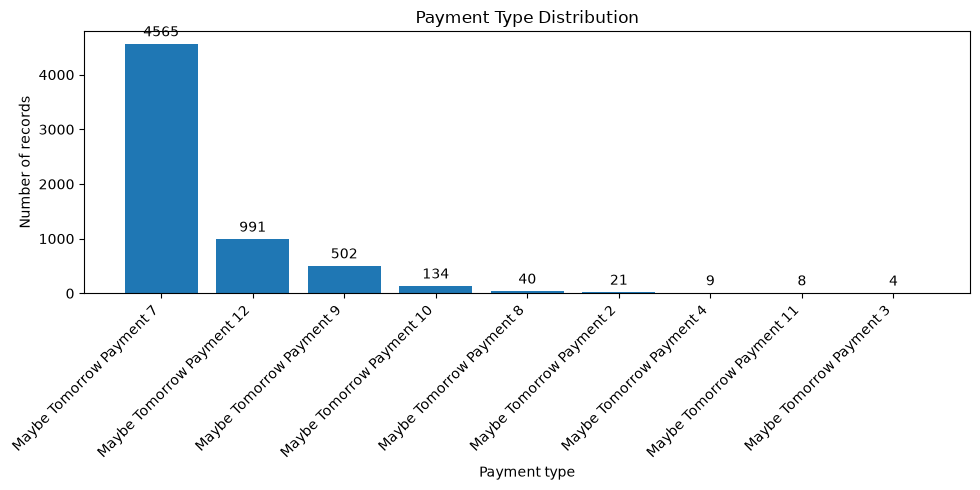

In [ ]:
payment_type = categorical_train["payment_type"]
payment_counts = payment_type.value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(payment_counts.index, payment_counts.values)

ax.set_title("Payment Type Distribution")
ax.set_xlabel("Payment type")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
ax.bar_label(ax.containers[0], padding=3)

fig.tight_layout()
plt.show()

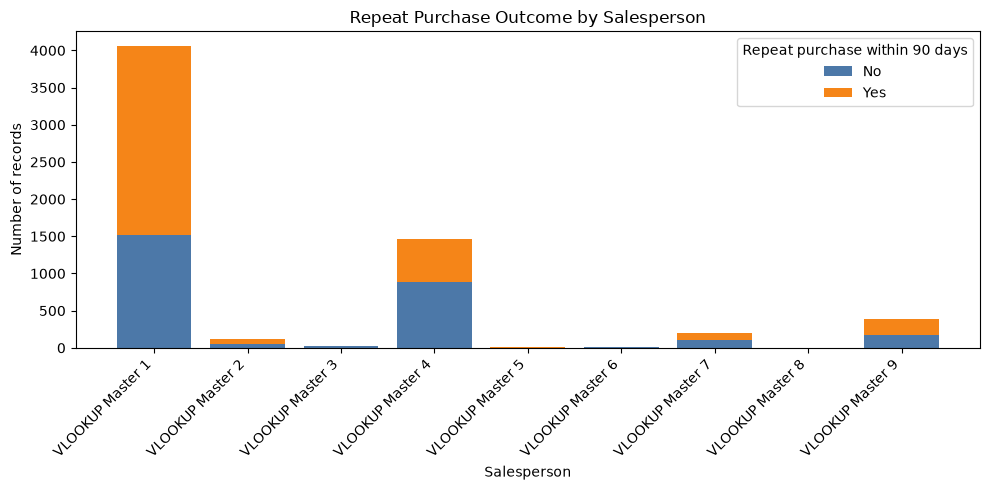

In [ ]:
salesperson_target_counts = pd.crosstab(
    train["salesperson"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)

x = np.arange(len(salesperson_target_counts))
no_counts = salesperson_target_counts[0]
yes_counts = salesperson_target_counts[1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, no_counts, label="No", color="#4C78A8")
ax.bar(x, yes_counts, bottom=no_counts, label="Yes", color="#F58518")

ax.set_title("Repeat Purchase Outcome by Salesperson")
ax.set_xlabel("Salesperson")
ax.set_ylabel("Number of records")
ax.set_xticks(x, salesperson_target_counts.index, rotation=45, ha="right")
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

The salesperson might affect the label (logically meaningful, but not statistically proven yet).

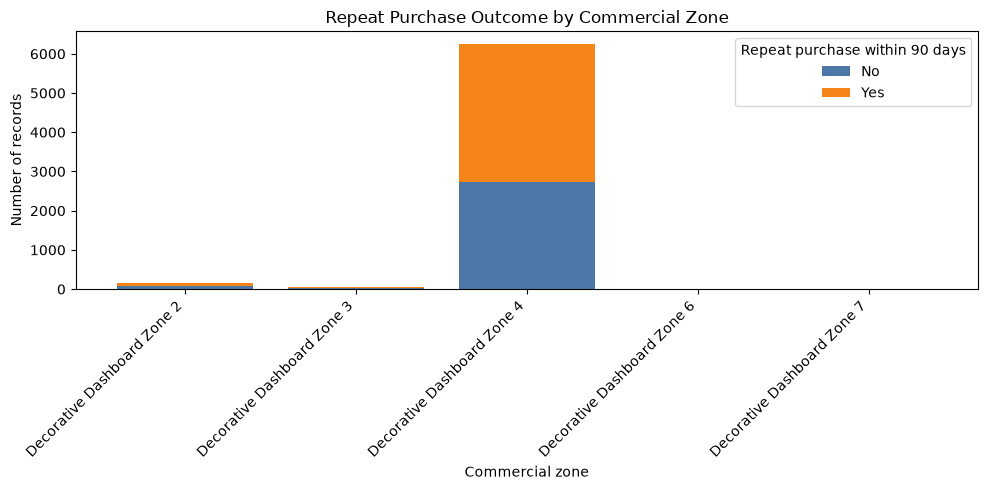

In [ ]:
commercial_zone_target_counts = pd.crosstab(
    train["commercial_zone"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)

x = np.arange(len(commercial_zone_target_counts))
no_counts = commercial_zone_target_counts[0]
yes_counts = commercial_zone_target_counts[1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, no_counts, label="No", color="#4C78A8")
ax.bar(x, yes_counts, bottom=no_counts, label="Yes", color="#F58518")

ax.set_title("Repeat Purchase Outcome by Commercial Zone")
ax.set_xlabel("Commercial zone")
ax.set_ylabel("Number of records")
ax.set_xticks(x, commercial_zone_target_counts.index, rotation=45, ha="right")
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

**`commercial_zone` has a highly skewed category distribution: nearly all non-missing observations are in Zone 4, with very few in the other zones.**

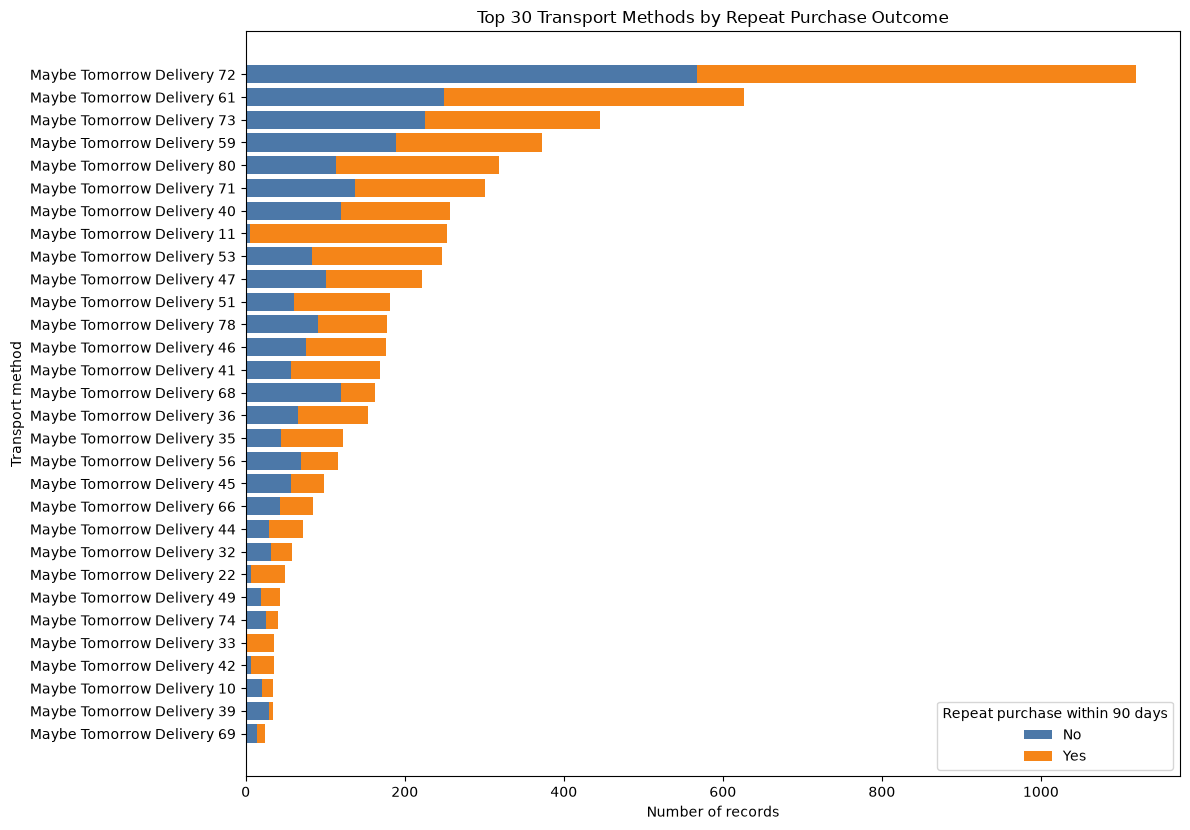

In [ ]:
transport_method_target_counts = pd.crosstab(
    train["transport_method"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)
transport_method_target_counts = transport_method_target_counts.loc[
    transport_method_target_counts.sum(axis=1).nlargest(30).index
]

y = np.arange(len(transport_method_target_counts))
no_counts = transport_method_target_counts[0]
yes_counts = transport_method_target_counts[1]

fig, ax = plt.subplots(
    figsize=(12, max(7, len(transport_method_target_counts) * 0.28))
)
ax.barh(y, no_counts, label="No", color="#4C78A8")
ax.barh(y, yes_counts, left=no_counts, label="Yes", color="#F58518")

ax.set_title("Top 30 Transport Methods by Repeat Purchase Outcome")
ax.set_xlabel("Number of records")
ax.set_ylabel("Transport method")
ax.set_yticks(y, transport_method_target_counts.index)
ax.invert_yaxis()
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

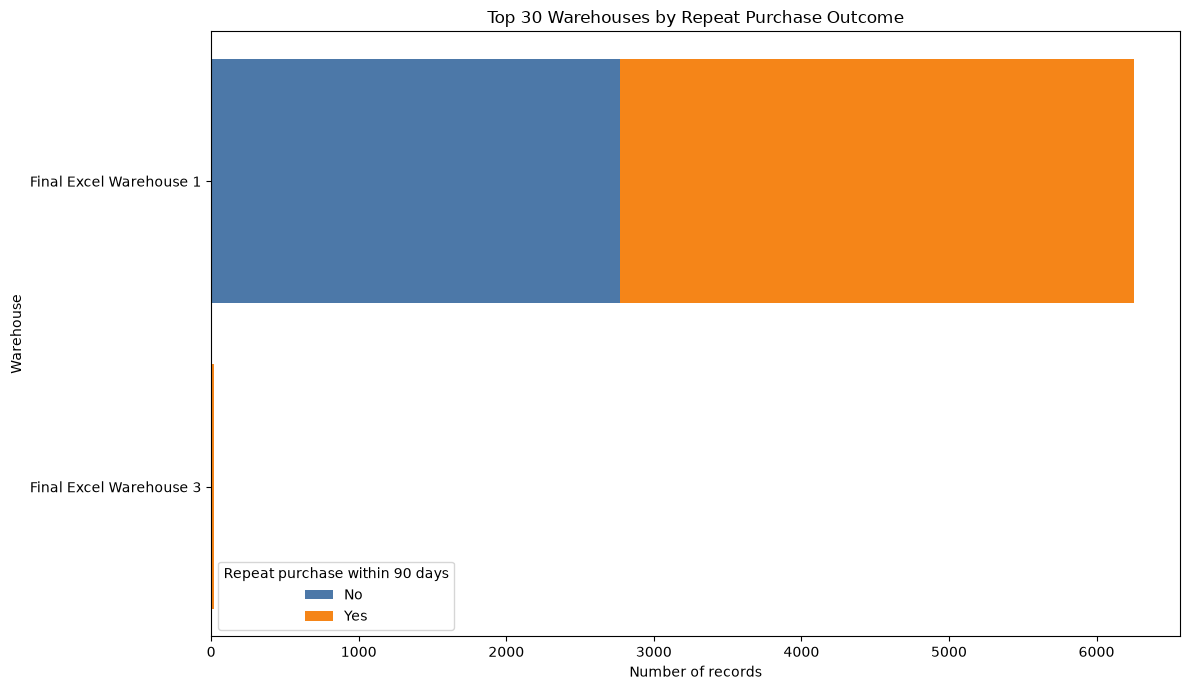

In [ ]:
warehouse_target_counts = pd.crosstab(
    train["warehouse"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)
warehouse_target_counts = warehouse_target_counts.loc[
    warehouse_target_counts.sum(axis=1).nlargest(30).index
]

y = np.arange(len(warehouse_target_counts))
no_counts = warehouse_target_counts[0]
yes_counts = warehouse_target_counts[1]

fig, ax = plt.subplots(
    figsize=(12, max(7, len(warehouse_target_counts) * 0.28))
)
ax.barh(y, no_counts, label="No", color="#4C78A8")
ax.barh(y, yes_counts, left=no_counts, label="Yes", color="#F58518")

ax.set_title("Top 30 Warehouses by Repeat Purchase Outcome")
ax.set_xlabel("Number of records")
ax.set_ylabel("Warehouse")
ax.set_yticks(y, warehouse_target_counts.index)
ax.invert_yaxis()
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

`warehouse` should probably be discarded: nearly all records are Warehouse 1, and Warehouse 3 is too small to learn patterns from.

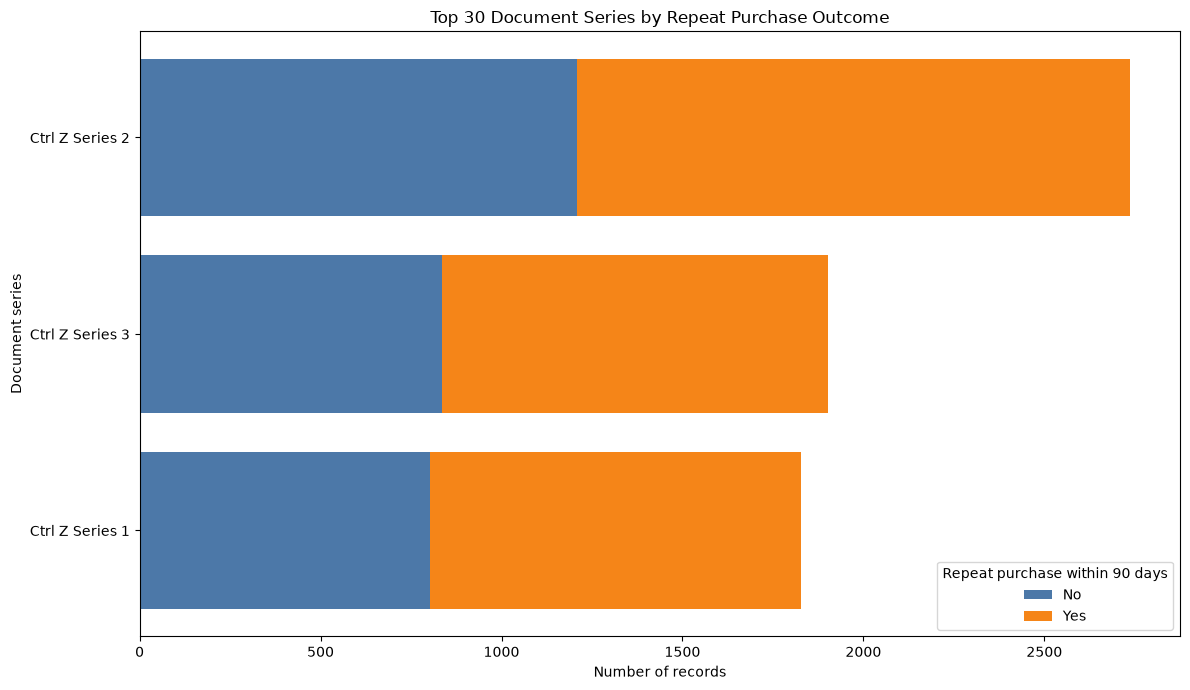

In [ ]:
document_series_target_counts = pd.crosstab(
    train["document_series"], train["repeat_purchase_90d"]
).reindex(columns=[0, 1], fill_value=0)
document_series_target_counts = document_series_target_counts.loc[
    document_series_target_counts.sum(axis=1).nlargest(30).index
]

y = np.arange(len(document_series_target_counts))
no_counts = document_series_target_counts[0]
yes_counts = document_series_target_counts[1]

fig, ax = plt.subplots(
    figsize=(12, max(7, len(document_series_target_counts) * 0.28))
)
ax.barh(y, no_counts, label="No", color="#4C78A8")
ax.barh(y, yes_counts, left=no_counts, label="Yes", color="#F58518")

ax.set_title("Top 30 Document Series by Repeat Purchase Outcome")
ax.set_xlabel("Number of records")
ax.set_ylabel("Document series")
ax.set_yticks(y, document_series_target_counts.index)
ax.invert_yaxis()
ax.legend(title="Repeat purchase within 90 days")

fig.tight_layout()
plt.show()

#### Client features (from `clientes.csv`)

Clients dataset shape: (1143, 13)

Client dataset preview:


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015



NaN values per client feature:
customer_type          1143
street                  598
island                  578
city                    546
postal_code             170
municipality            159
commercial_region       114
postal_area              71
address                   6
customer_id               0
country_or_region         0
company_name              0
customer_since_year       0

Client numerical feature summary:
                       count  missing     mean  std      min      25%   median      75%      max  IQR
customer_since_year 1,143.00        0 2,017.00 2.97 2,015.00 2,015.00 2,015.00 2,018.00 2,026.00 3.00
Joined shape: (6534, 51)
Rows matched to a client: 6,534 / 6,534

Repeat-purchase rate by common client categories (minimum 30 records):
          feature                                        category  records repeat_rate
country_or_region         Country CT10: Land of The Final Version     6321       56.5%
country_or_region          Country CT5: Land of The Fi

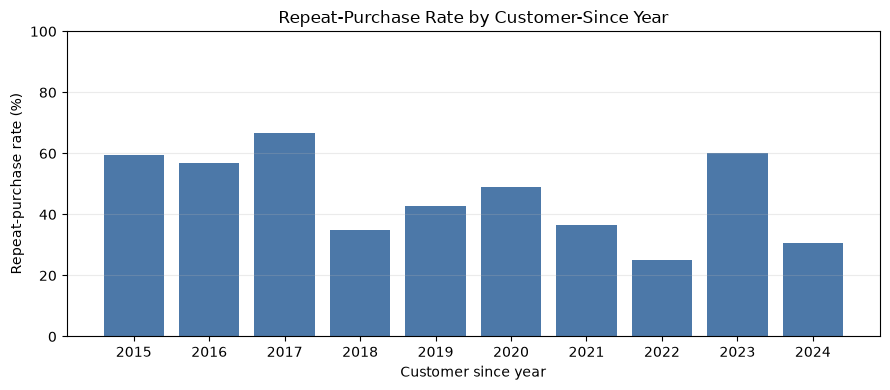

In [ ]:
print("Clients dataset shape:", clients.shape)
print("\nClient dataset preview:")
display(clients.head())

client_missing_counts = clients.isna().sum().sort_values(ascending=False)
print("\nNaN values per client feature:")
print(client_missing_counts.to_string())

client_numeric_cols = [
    column for column in clients.select_dtypes(include="number").columns
    if column != "customer_id" and clients[column].notna().any()
]
client_numerical = clients[client_numeric_cols]
client_summary = client_numerical.describe().T.rename(
    columns={"50%": "median"}
)
client_summary["missing"] = client_numerical.isna().sum()
client_summary["IQR"] = client_summary["75%"] - client_summary["25%"]
client_summary = client_summary[
    ["count", "missing", "mean", "std", "min", "25%", "median", "75%", "max", "IQR"]
]
print("\nClient numerical feature summary:")
print(client_summary.to_string(float_format=lambda value: f"{value:,.2f}"))

matched_clients = train["country_or_region"].notna().sum()
print(f"Joined shape: {train.shape}")
print(f"Rows matched to a client: {matched_clients:,} / {len(train):,}")

client_categorical_features = [
    column for column in clients.select_dtypes(include=["object", "category", "string"]).columns
    if clients[column].notna().any() and column in train.columns
]
minimum_category_rows = 30
maximum_categories = 5
relationship_tables = []

for feature in client_categorical_features:
    categories = train[feature].astype("string").fillna("Missing")
    common_categories = categories.value_counts()
    common_categories = common_categories[common_categories >= minimum_category_rows]
    common_categories = common_categories.head(maximum_categories).index
    grouped_categories = categories.where(categories.isin(common_categories), "Other / rare")
    feature_summary = (
        pd.DataFrame({"category": grouped_categories,
                      "repeat_purchase_90d": train[target]})
        .groupby("category")["repeat_purchase_90d"]
        .agg(records="size", repeat_rate="mean")
        .reset_index()
    )
    feature_summary.insert(0, "feature", feature)
    relationship_tables.append(feature_summary)

client_category_relationships = pd.concat(relationship_tables, ignore_index=True)
client_category_relationships["repeat_rate"] *= 100
print("\nRepeat-purchase rate by common client categories (minimum 30 records):")
print(client_category_relationships.to_string(
    index=False,
    formatters={"repeat_rate": "{:.1f}%".format},
))

year_summary = (
    train.groupby("customer_since_year")["repeat_purchase_90d"]
    .agg(records="size", repeat_rate="mean")
)
year_summary["repeat_rate"] *= 100
print("\nRepeat-purchase rate by customer-since year:")
print(year_summary.to_string(formatters={"repeat_rate": "{:.1f}%".format}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(year_summary.index.astype(str), year_summary["repeat_rate"], color="#4C78A8")
ax.set_title("Repeat-Purchase Rate by Customer-Since Year")
ax.set_xlabel("Customer since year")
ax.set_ylabel("Repeat-purchase rate (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

The bars show the **observed repeat-purchase rate** for each country or region:

$$\text{repeat rate} = \frac{\text{customers with repeat\_purchase\_90d = 1}}{\text{customers in that group}} \times 100$$

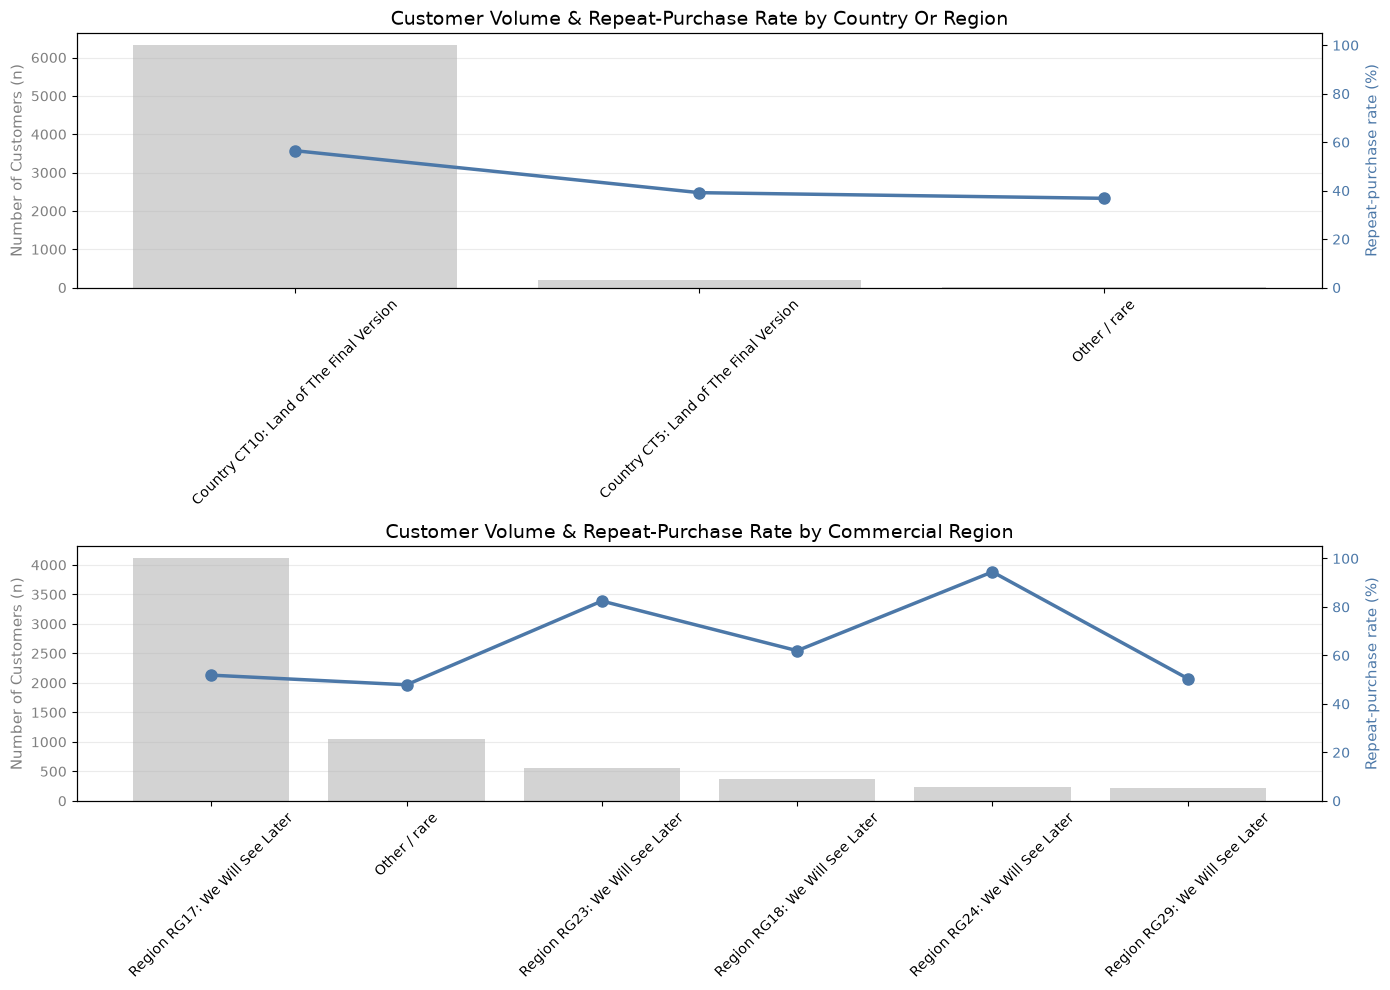

In [ ]:
location_features = ["country_or_region", "commercial_region"]
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

for ax1, feature in zip(axes, location_features):
    summary = client_category_relationships[
        client_category_relationships["feature"] == feature
    ].sort_values("records", ascending=False)

    categories = summary["category"]
    records = summary["records"]
    rates = summary["repeat_rate"]

    # 1st axis: number of customers (bars)
    ax1.bar(categories, records, color="#d3d3d3", label="Number of Customers")
    ax1.set_ylabel("Number of Customers (n)", color="gray", fontsize=11)
    ax1.tick_params(axis='y', labelcolor="gray")
    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(axis="y", alpha=0.25)

    # 2nd axis: repeat rate (line)
    ax2 = ax1.twinx()
    ax2.plot(categories, rates, color="#4C78A8", marker='o', linewidth=2.5, markersize=8, label="Repeat Rate (%)")
    ax2.set_ylabel("Repeat-purchase rate (%)", color="#4C78A8", fontsize=11)
    ax2.set_ylim(0, 105)
    ax2.tick_params(axis='y', labelcolor="#4C78A8")

    ax1.set_title(f"Customer Volume & Repeat-Purchase Rate by {feature.replace('_', ' ').title()}", fontsize=14)

fig.tight_layout()
plt.show()

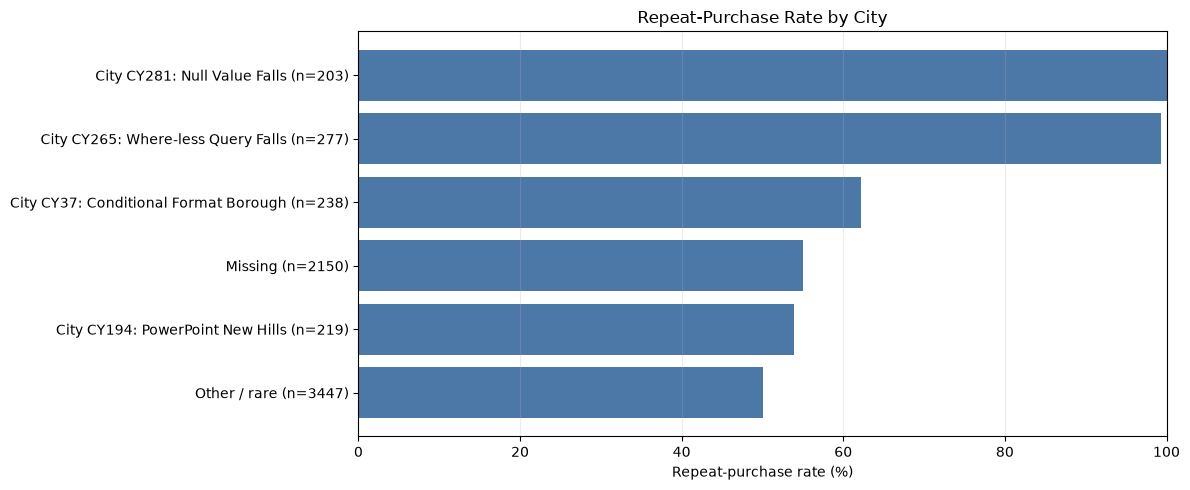


Distinct customers by city group (repeat_purchase_90d = 1 at least once):
                                       customers  repeat_buyers
city_group                                                     
Other / rare                                 352            207
City CY194: PowerPoint New Hills              11              9
Missing                                      236            126
City CY37: Conditional Format Borough          9              8
City CY265: Where-less Query Falls             1              1
City CY281: Null Value Falls                   1              1


In [ ]:
city_summary = client_category_relationships[
    client_category_relationships["feature"] == "city"
].sort_values("repeat_rate")
city_labels = [
    f"{category} (n={records})"
    for category, records in zip(city_summary["category"], city_summary["records"])
]

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(city_labels, city_summary["repeat_rate"], color="#4C78A8")
ax.set_title("Repeat-Purchase Rate by City")
ax.set_xlabel("Repeat-purchase rate (%)")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

# Count each customer once, even if they have multiple positive training rows.
city_row_values = train["city"].astype("string").fillna("Missing")
common_city_categories = city_row_values.value_counts()
common_city_categories = common_city_categories[
    common_city_categories >= minimum_category_rows
].head(maximum_categories).index
customer_repeat_status = (
    fixed_train.groupby("customer_id")[target]
    .max()
    .rename("repeat_buyer")
    .reset_index()
)
buyers_by_city = clients[["customer_id", "city"]].merge(
    customer_repeat_status,
    on="customer_id",
    how="inner",
    validate="one_to_one",
)
buyer_city_values = buyers_by_city["city"].astype("string").fillna("Missing")
buyers_by_city["city_group"] = buyer_city_values.where(
    buyer_city_values.isin(common_city_categories), "Other / rare"
)
city_customer_counts = buyers_by_city.groupby("city_group").agg(
    customers=("customer_id", "nunique"),
    repeat_buyers=("repeat_buyer", "sum"),
).reindex(city_summary["category"], fill_value=0).astype(int)
city_customer_counts.index.name = "city_group"
print("\nDistinct customers by city group (repeat_purchase_90d = 1 at least once):")
print(city_customer_counts.to_string())

**Caution:** City CY281's 100% rate comes from 203 records for just one customer, not 203 different customers. It does not mean customers in that city always repeat. **This observation can be misleading.**

### Multivariate analysis
Correlation analysis (Spearman / Pearson) needs cleaned data, so the active version is in **Section III (Filter Methods, Numerical vs. Numerical)**. The earlier version on uncleaned data is kept below for reference.

In [ ]:
# # unclean data
# correlation_data = fixed_train.merge(
#     clients,
#     on="customer_id",
#     how="left",
#     validate="many_to_one",
# )
# excluded_features = ["ID", "customer_id", "random_noise"]
# numeric_features = correlation_data.select_dtypes(include="number").drop(
#     columns=excluded_features, errors="ignore"
# )
# numeric_features = numeric_features.loc[
#     :, numeric_features.nunique(dropna=True) > 1
# ]
# corr_matrix = numeric_features.corr()
#
# plt.figure(figsize=(14, 12))
# sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
# plt.title("Correlation Matrix of Numeric Transaction and Client Features")
# plt.tight_layout()
# plt.show()
#
# print(corr_matrix["repeat_purchase_90d"].sort_values(ascending=False))

---
# II. Data Cleaning & Pre-processing
## II.1 Missing & Anomalous Data
We improve data quality by removing unexplainable entries and dropping irrelevant features (identifiers).

### Illogical / too-corrupted data
- **`spend_365d`** has an extreme value of -159,115.18€ (it can be negative for refunds, but this is extreme, especially if larger than total spend).
- **`prior_mean_purchase_value`** & **`spend_365d`** have values above total spend, which is unexplainable.
- **Illogical orderings:** `prior_total_spend` < `spend_365d`, or `spend_365d` < `spend_180d`, or `spend_180d` < `spend_90d`.

### Useless features
`commercial_zone`, `random_noise`

In [ ]:
# Check the invoice equations. Tolerance of 0.01 accounts for 1-cent rounding differences
tolerance = 1e-2

# 1. Verify the Net Total (Total Liquido)
eq1_valid = np.isclose(
    train['Total Liquido'],
    train['Total Bruto'] - train['Total Desc_ Linha'] - train['Total Desc_ Global'],
    atol=tolerance,
    equal_nan=False
)

# 2. Verify the Final Payable Amount (Total a Pagar)
eq2_valid = np.isclose(
    train['Total a Pagar'],
    train['Total Liquido'] + train['Total Imp_'] + train['Total Portes'],
    atol=tolerance,
    equal_nan=False
)

# 3. Rows where either equation FAILS
corrupted_rows = train[~(eq1_valid & eq2_valid)]

print(f"Found {len(corrupted_rows)} rows with mathematical inconsistencies:")

cols_to_inspect = [
    'Total Bruto', 'Total Desc_ Linha', 'Total Desc_ Global',
    'Total Liquido', 'Total Imp_', 'Total Portes', 'Total a Pagar'
]
corrupted_rows[cols_to_inspect].sort_values(by="Total Bruto", ascending=False).head()

Found 1118 rows with mathematical inconsistencies:


,Total Bruto,Total Desc_ Linha,Total Desc_ Global,Total Liquido,Total Imp_,Total Portes,Total a Pagar
1808,12500.00,3720.00,0.0,8780.00,0.00,100.00,8780.00
3802,9323.35,3704.89,0.0,5618.46,0.00,45.00,5618.46
5542,7860.48,3386.82,0.0,4473.66,0.00,181.06,4473.66
1344,7001.34,2550.01,0.0,4451.33,1023.81,18.70,5475.14
665,5643.43,2193.48,0.0,3449.95,0.00,159.73,3449.95


**Too unclean; verify whether the 1 billion value is an error or actual.**

These rows are corrupted. Imputation (mean, median, KNN or 0) doesn't work well because the features depend on each other (gross total, net total, taxes, shipping) and would need massive transformation. Also the mean is ~1 billion while the maximum total paid is 102,493.92.

The best solution is to not force data transformation but to remove the outliers (bug).

### Missing values

In [ ]:
train.isna().sum().sort_values(ascending=False)

customer_type                     6534
street                            3834
island                            2211
city                              2150
prior_std_gap_days                1478
prior_mean_gap_days               1308
prior_std_purchase_value          1113
prior_mean_purchase_value          862
days_since_previous_purchase       861
prior_max_purchase_value           668
prior_min_purchase_value           668
postal_area                        278
transport_method                   261
warehouse                          260
spend_365d                         260
payment_type                       260
salesperson                        259
postal_code                        225
municipality                       217
commercial_zone                     65
Total a Pagar                       65
spend_180d                          65
document_series                     65
purchase_date                       65
random_noise                        65
purchase_count_365d      

Auto-discarding these features due to too many missing values (also street is hard to predict from city or other features):
- `customer_type` (6534 missing)
- `street` (3834 missing)

Discarding due to irrelevance to model prediction:
- `ID`
- `customer_id`
- `random_noise`

In [ ]:
#count number of NaN for each row 
missing_per_row = fixed_merged.isna().sum(axis=1)

#Count number of rows for how many features are missing
missing_per_row=missing_per_row.value_counts()

#Create a df for pure visualization
df_missing = (
    missing_per_row
    .rename_axis("n_features_missing")
    .reset_index(name="n_rows_affected")
)

#printed using to_string to remove the index(useless for presentation)
print(df_missing.sort_values("n_features_missing",ascending=False).to_string(index=False))


 n_features_missing  n_rows_affected
                 40                4
                 39               16
                 38               28
                 37               17
                 15                1
                 14                9
                 13               15
                 12               24
                 11               64
                 10              216
                  9              227
                  8               95
                  7               84
                  6              245
                  5              329
                  4              719
                  3             1782
                  2             1950
                  1              709


In [ ]:
# Rows that have more than 15 missing values
heavy_missing_rows = train[train.isna().sum(axis=1) > 15]

print(f"Number of rows missing 15+ features : {heavy_missing_rows[[ 'purchase_date', 'Total a Pagar']].size} these rows are to be deleted, its missing almost all features except in customer. \n")
heavy_missing_rows.head(3)

Number of rows missing 15+ features : 130 these rows are to be deleted, its missing almost all features except in customer. 



,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000457,NaN,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS4: The Pivot Archipelago,Municipality MU15: Council of Last Minute Edits,City CY180: Frozen Pane Grove,Postal area PA267: Hidden Sheet Sector,Postal code PC778: #REF! Delivery Route,Street ST171: VLOOKUP Walk,Address AD456: Cell Without a Home,NaN,Excel Is Not A Database Ltd 9,2015
484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000560,NaN,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS4: The Pivot Archipelago,Municipality MU15: Council of Last Minute Edits,City CY180: Frozen Pane Grove,Postal area PA267: Hidden Sheet Sector,Postal code PC778: #REF! Delivery Route,Street ST171: VLOOKUP Walk,Address AD456: Cell Without a Home,NaN,Excel Is Not A Database Ltd 9,2015
582,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000678,NaN,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS8: The Pivot Archipelago,Municipality MU1: Council of Last Minute Edits,City CY37: Conditional Format Borough,Postal area PA259: Hidden Sheet Sector,Postal code PC628: #REF! Delivery Route,NaN,Address AD106: Cell Without a Home,NaN,Excel Is Not A Database Ltd 679,2015


In [ ]:
# Features to drop
columns_to_drop = [
    'customer_type',
    'street',
    'ID',
    'customer_id',
    'random_noise'
]

train = train.drop(columns=columns_to_drop, errors='ignore')
print(train.shape)

(6534, 46)


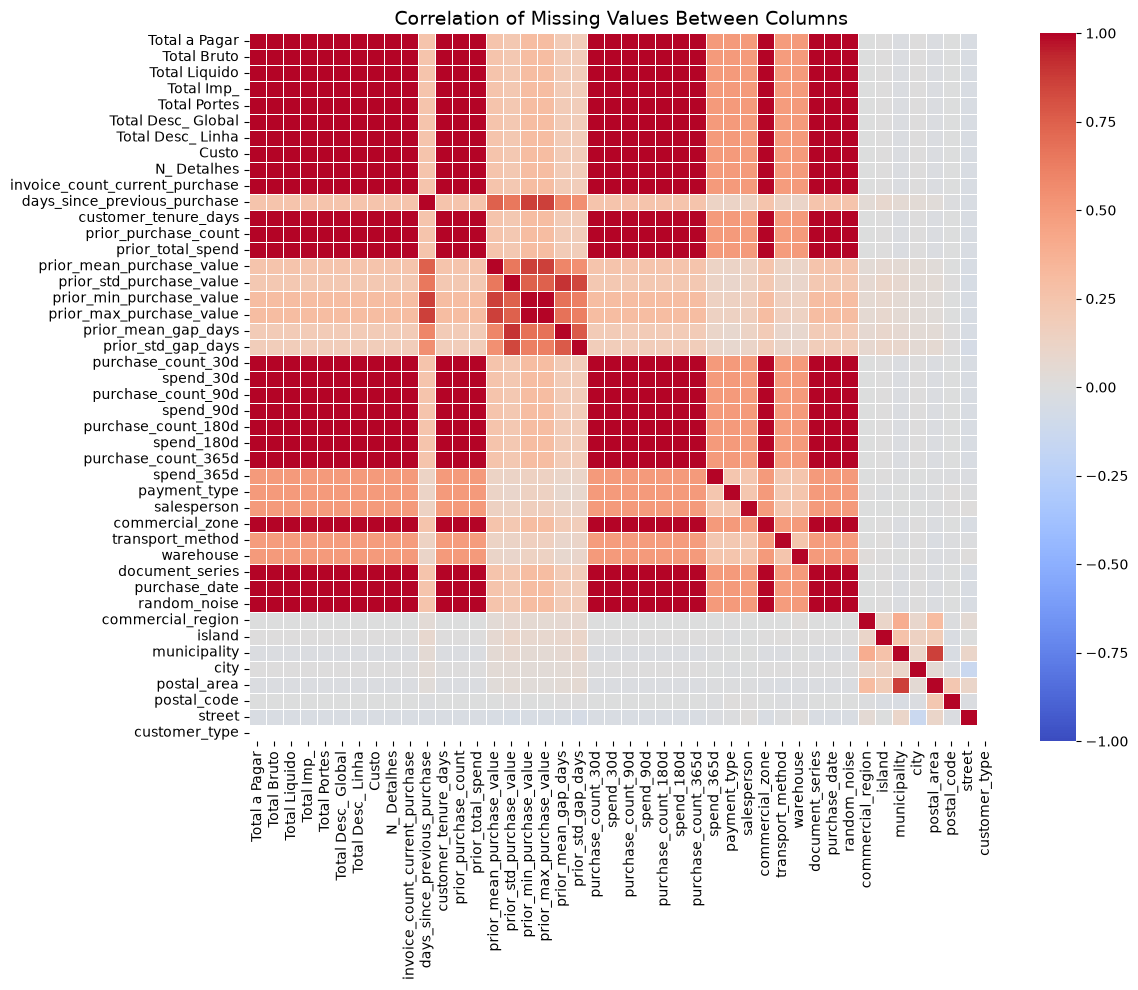

In [ ]:
# Correlation of missingness
plt.figure(figsize=(12, 10))
#show only features missing values (non missing features will be meaningless here because they will just leave blank space)
cols_with_missing = fixed_merged.columns[fixed_merged.isna().any()]
missing_corr = fixed_merged[cols_with_missing].isna().corr()


sns.heatmap(missing_corr, annot=False, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation of Missing Values Between Columns", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# Drop all rows where 'Total a Pagar' is missing
train = train.dropna(subset=['Total a Pagar'])
print(train.isna().sum())


Total a Pagar                        0
Total Bruto                          0
Total Liquido                        0
Total Imp_                           0
Total Portes                         0
Total Desc_ Global                   0
Total Desc_ Linha                    0
Custo                                0
N_ Detalhes                          0
invoice_count_current_purchase       0
repeat_purchase_90d                  0
days_since_previous_purchase       796
customer_tenure_days                 0
prior_purchase_count                 0
prior_total_spend                    0
prior_mean_purchase_value          797
prior_std_purchase_value          1048
prior_min_purchase_value           603
prior_max_purchase_value           603
prior_mean_gap_days               1243
prior_std_gap_days                1413
purchase_count_30d                   0
spend_30d                            0
purchase_count_90d                   0
spend_90d                            0
purchase_count_180d      

High missingness correlation across 23 features: these values aren't imputable nor synthesizable.

### Removing implausible rows

In [ ]:
# Rows where the mean is impossibly greater than the total spend, etc.
corrupted_prior = fixed_train[fixed_train["prior_mean_purchase_value"] > fixed_train["prior_total_spend"]].index

corrupted_spend_365d = fixed_train[fixed_train["spend_365d"] > fixed_train["prior_total_spend"]]["spend_365d"].index
corrupted_purchase_count_180d = fixed_train[fixed_train["spend_180d"] > fixed_train["spend_365d"]]["spend_180d"].index
corrupted_purchase_count_90d = fixed_train[fixed_train["spend_90d"] > fixed_train["spend_180d"]]["spend_90d"].index
corrupted_prior_max_purchase_value = fixed_train[fixed_train["prior_max_purchase_value"] > fixed_train["prior_total_spend"]]["prior_max_purchase_value"].index
corrupted_prior_mean_purchase_value = fixed_train[fixed_train["prior_mean_purchase_value"] < 0]["prior_mean_purchase_value"].index
print(f"Cases Where Spend of 365>total Spend: {corrupted_spend_365d.value_counts().sum()}\nCases where spend180>spend365: {corrupted_purchase_count_180d.value_counts().sum()}\nCases where spend90>spend 180: {corrupted_purchase_count_90d.value_counts().sum()}\nCases where max spend is bigger than total spend: {corrupted_prior_max_purchase_value.value_counts().sum()}\nCases where mean spending is negative: {corrupted_prior_mean_purchase_value.value_counts().sum()}")
# Show all columns to identify the anomaly
pd.set_option('display.max_columns', None)
all_corrupted_index = (
    corrupted_prior.union(corrupted_spend_365d)
    .union(corrupted_purchase_count_180d)
    .union(corrupted_purchase_count_90d)
    .union(corrupted_prior_max_purchase_value)
    .union(corrupted_prior_mean_purchase_value)
    .union(heavy_missing_rows.index)
    .intersection(train.index)  # avoid error from dropping already-dropped rows
)
fixed_train.loc[all_corrupted_index].head(3)

Cases Where Spend of 365>total Spend: 251
Cases where spend180>spend365: 15
Cases where spend90>spend 180: 0
Cases where max spend is bigger than total spend: 116
Cases where mean spending is negative: 16


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
8,962.63,786.27,782.63,180.00,0.0,0.0,3.64,496.926279,46.0,1.0,0,223.0,742.0,8.0,12487.24,1560.905000,1035.729065,130.18,3356.83,74.142857,57.831446,0.0,0.0,0.0,0.00,0.0,0.00,3.0,53906.674517,796571,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 3,2017-11-11,10000011,-0.519772
14,2460.00,2000.00,2000.00,460.00,0.0,0.0,0.00,0.000000,1.0,1.0,1,49.0,1277.0,31.0,3414.56,-110.147097,124.138784,0.93,552.37,40.933333,51.012462,0.0,0.0,3.0,194.64,6.0,535.93,13.0,1019.820000,239651,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 22,Final Excel Warehouse 1,Ctrl Z Series 2,2021-09-24,10000018,0.093198
24,2430.26,2404.29,1975.82,454.44,0.0,0.0,428.47,584.657046,65.0,1.0,1,41.0,220.0,6.0,5520.15,920.025000,859.127283,128.78,2456.68,NaN,27.770488,0.0,0.0,2.0,1509.54,4.0,4095.00,6.0,5520.150000,227020,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 1,2017-11-11,10000031,-0.225723


In [ ]:
train = train.drop(index=all_corrupted_index)

### Post-cleaning summary, distributions and outliers

In [ ]:
target = "repeat_purchase_90d"
exclude = [target, "customer_id", "ID"]

numerical_cols = (
    train.select_dtypes(include="number")
         .columns.drop(exclude, errors="ignore")
         .tolist()
)

numerical_train = train[numerical_cols]
numerical_summary = numerical_train.describe().T.rename(
    columns={"50%": "median"}
)
numerical_summary["missing"] = numerical_train.isna().sum()
numerical_summary["IQR"] = numerical_summary["75%"] - numerical_summary["25%"]
numerical_summary = numerical_summary[
    ["count", "missing", "mean", "std", "min", "25%", "median", "75%", "max", "IQR"]
]
print(numerical_summary.to_string(float_format=lambda value: f"{value:,.2f}"))

                                  count  missing      mean       std      min      25%   median       75%        max       IQR
Total a Pagar                  6,088.00        0    931.31  1,340.61     0.93   190.96   480.99  1,103.05  22,297.21    912.09
Total Bruto                    6,088.00        0    889.70  1,330.35     0.83   176.74   448.35  1,048.09  21,578.28    871.36
Total Liquido                  6,088.00        0    777.97  1,141.06     0.76   155.40   394.09    911.22  18,127.81    755.82
Total Imp_                     6,088.00        0    153.33    225.99     0.00    30.41    80.50    187.12   4,169.40    156.71
Total Portes                   6,088.00        0      1.14      5.64     0.00     0.00     0.00      0.00     181.06      0.00
Total Desc_ Global             6,088.00        0      0.36      5.22     0.00     0.00     0.00      0.00     218.49      0.00
Total Desc_ Linha              6,088.00        0    111.36    287.98     0.00     0.00    12.75     90.14   4,1

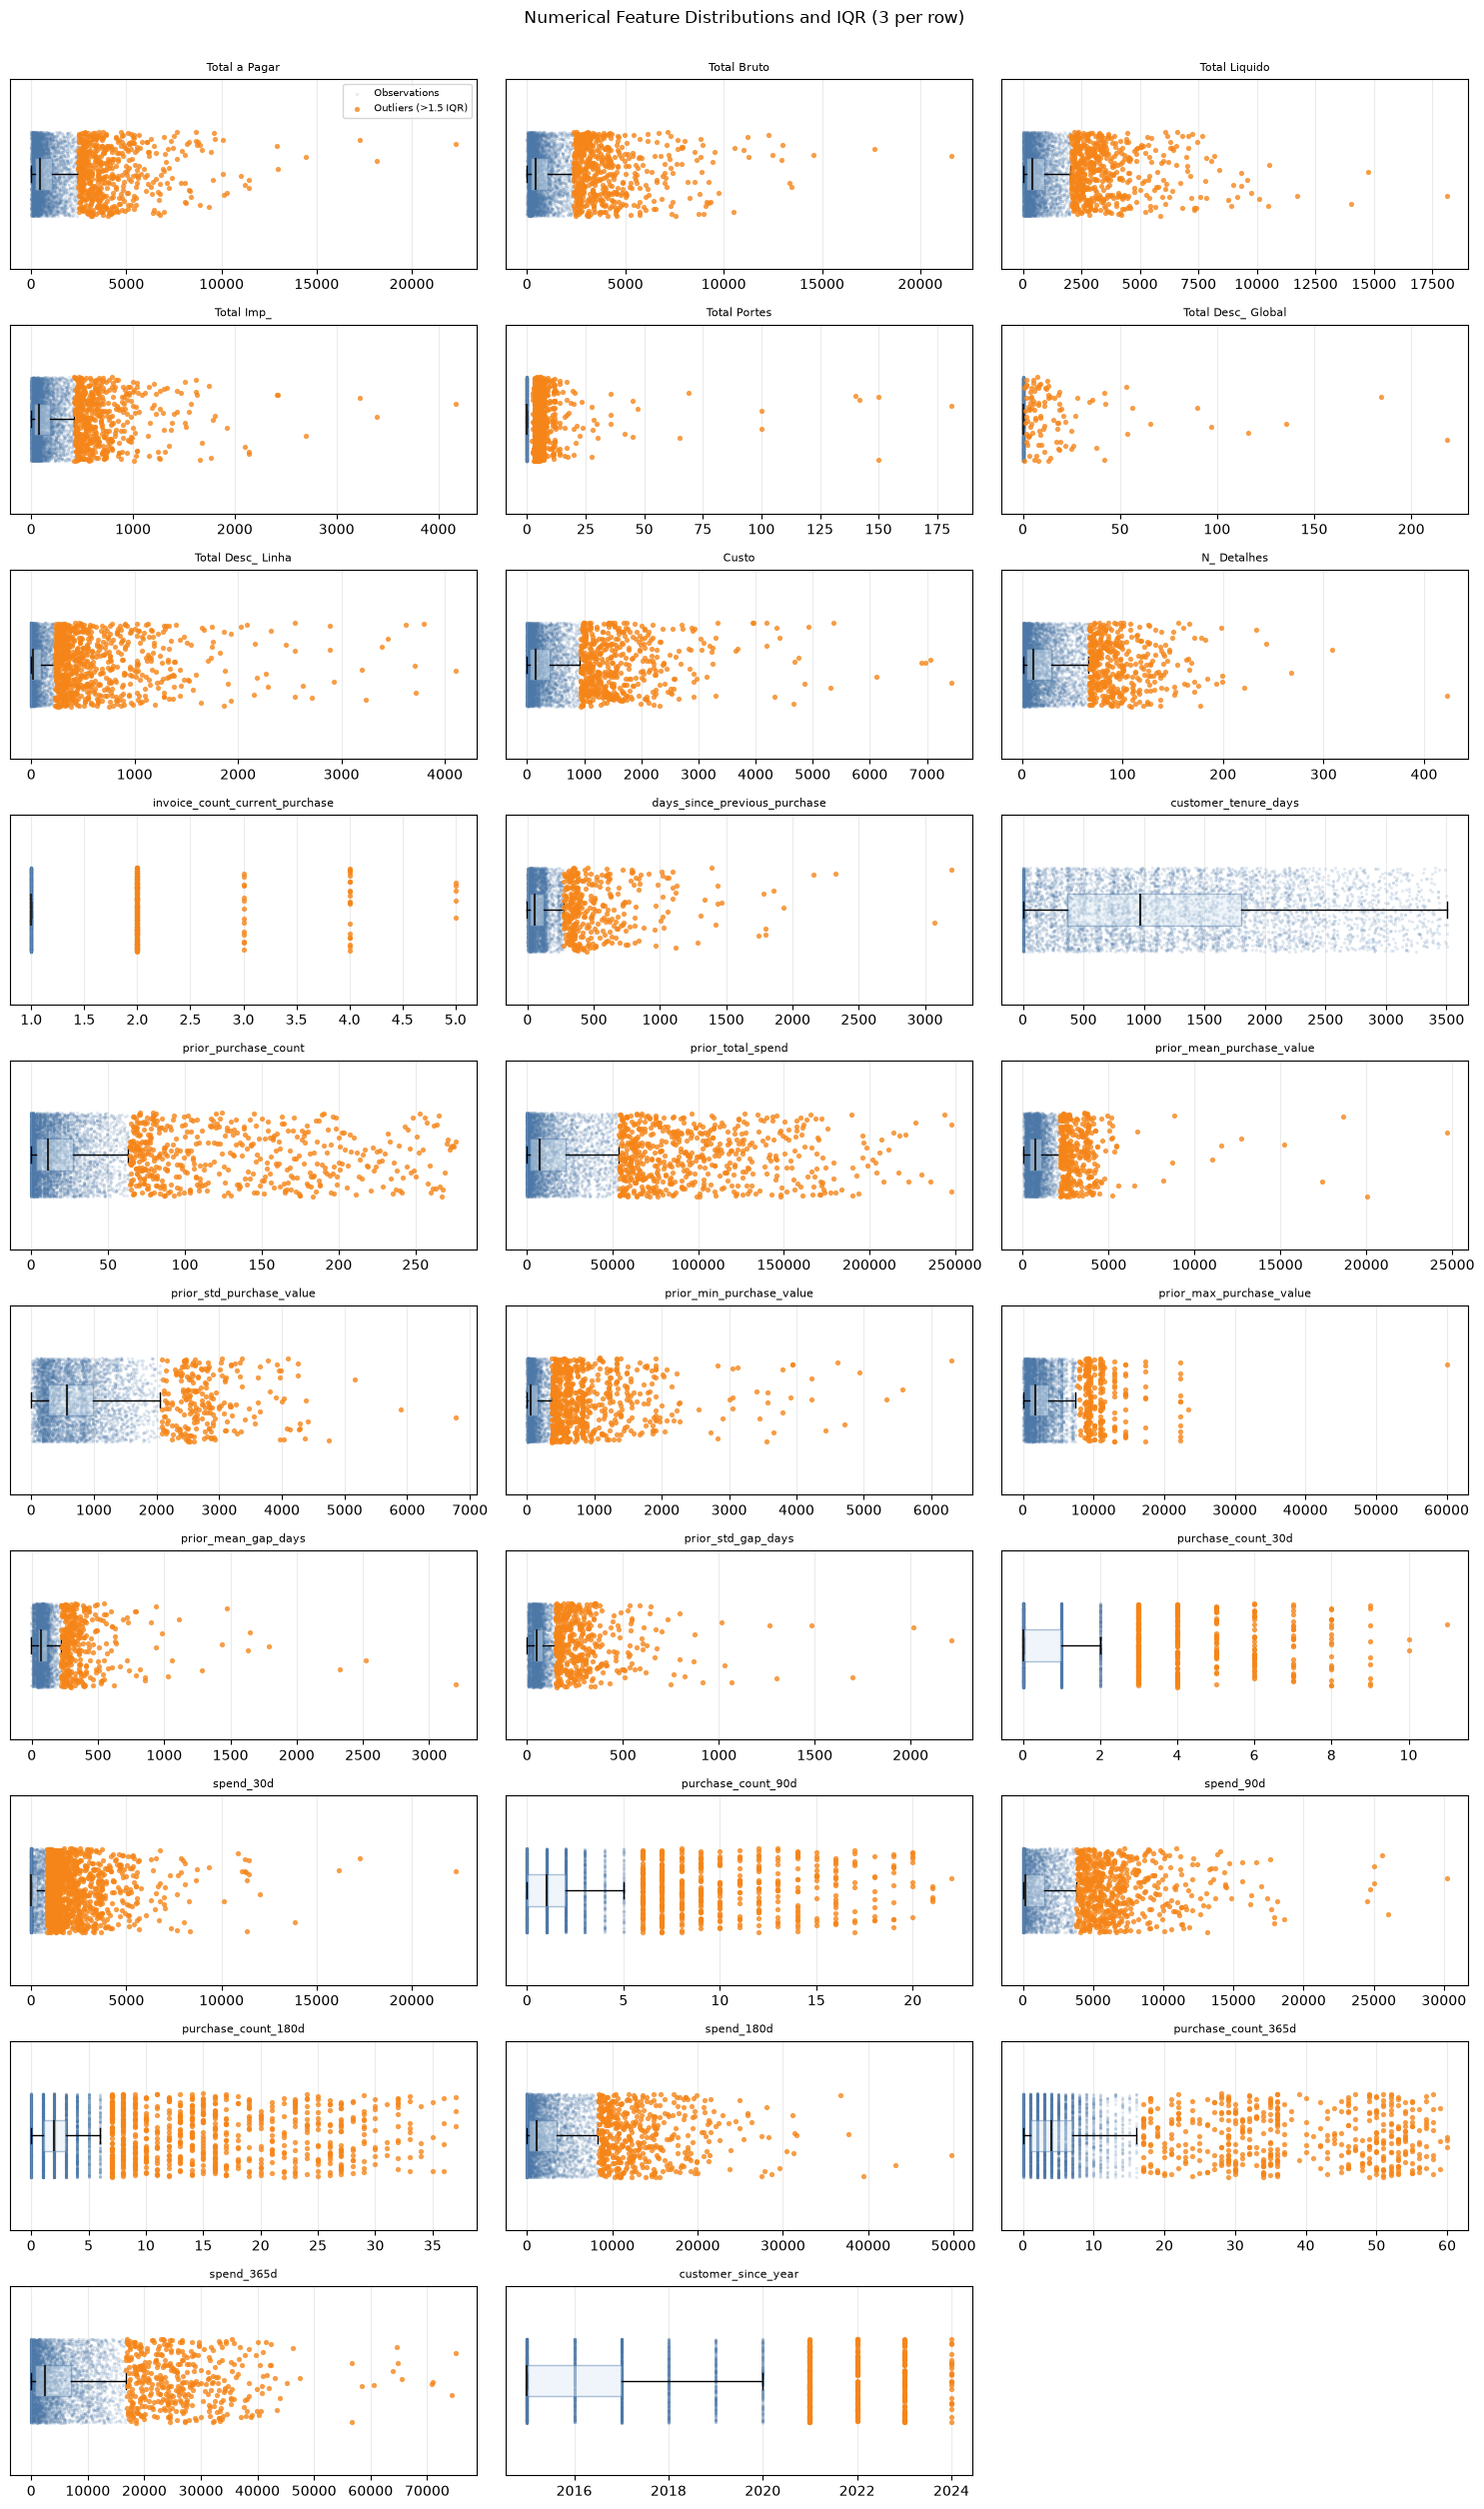

In [ ]:
plot_columns = 3
plot_rows = (len(numerical_cols) + plot_columns - 1) // plot_columns
fig, axes = plt.subplots(
    plot_rows, plot_columns,
    figsize=(15, plot_rows * 2.5),
    squeeze=False,
)
rng = np.random.default_rng(42)

for feature_index, (ax, feature) in enumerate(zip(axes.flat, numerical_cols)):
    values = numerical_train[feature].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_mask = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    jitter = rng.uniform(-0.2, 0.2, size=len(values))

    ax.boxplot(
        values,
        positions=[1],
        orientation="horizontal",
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": "#DCEAF4", "edgecolor": "#4C78A8", "alpha": 0.45},
        medianprops={"color": "#222222", "linewidth": 1.5},
    )
    ax.scatter(
        values[~outlier_mask], 1 + jitter[~outlier_mask],
        s=5, alpha=0.16, color="#4C78A8", linewidths=0,
        label="Observations" if feature_index == 0 else None,
        rasterized=True,
    )
    ax.scatter(
        values[outlier_mask], 1 + jitter[outlier_mask],
        s=14, alpha=0.8, color="#F58518", linewidths=0,
        label="Outliers (>1.5 IQR)" if feature_index == 0 else None,
        zorder=3,
    )
    ax.set_title(feature, fontsize=8)
    ax.set_yticks([])
    ax.set_ylim(0.55, 1.45)
    ax.grid(axis="x", alpha=0.25)

for ax in axes.flat[len(numerical_cols):]:
    ax.set_visible(False)

axes.flat[0].legend(loc="upper right", fontsize=7)
fig.suptitle("Numerical Feature Distributions and IQR (3 per row)", y=1.002)
fig.tight_layout()
plt.show()

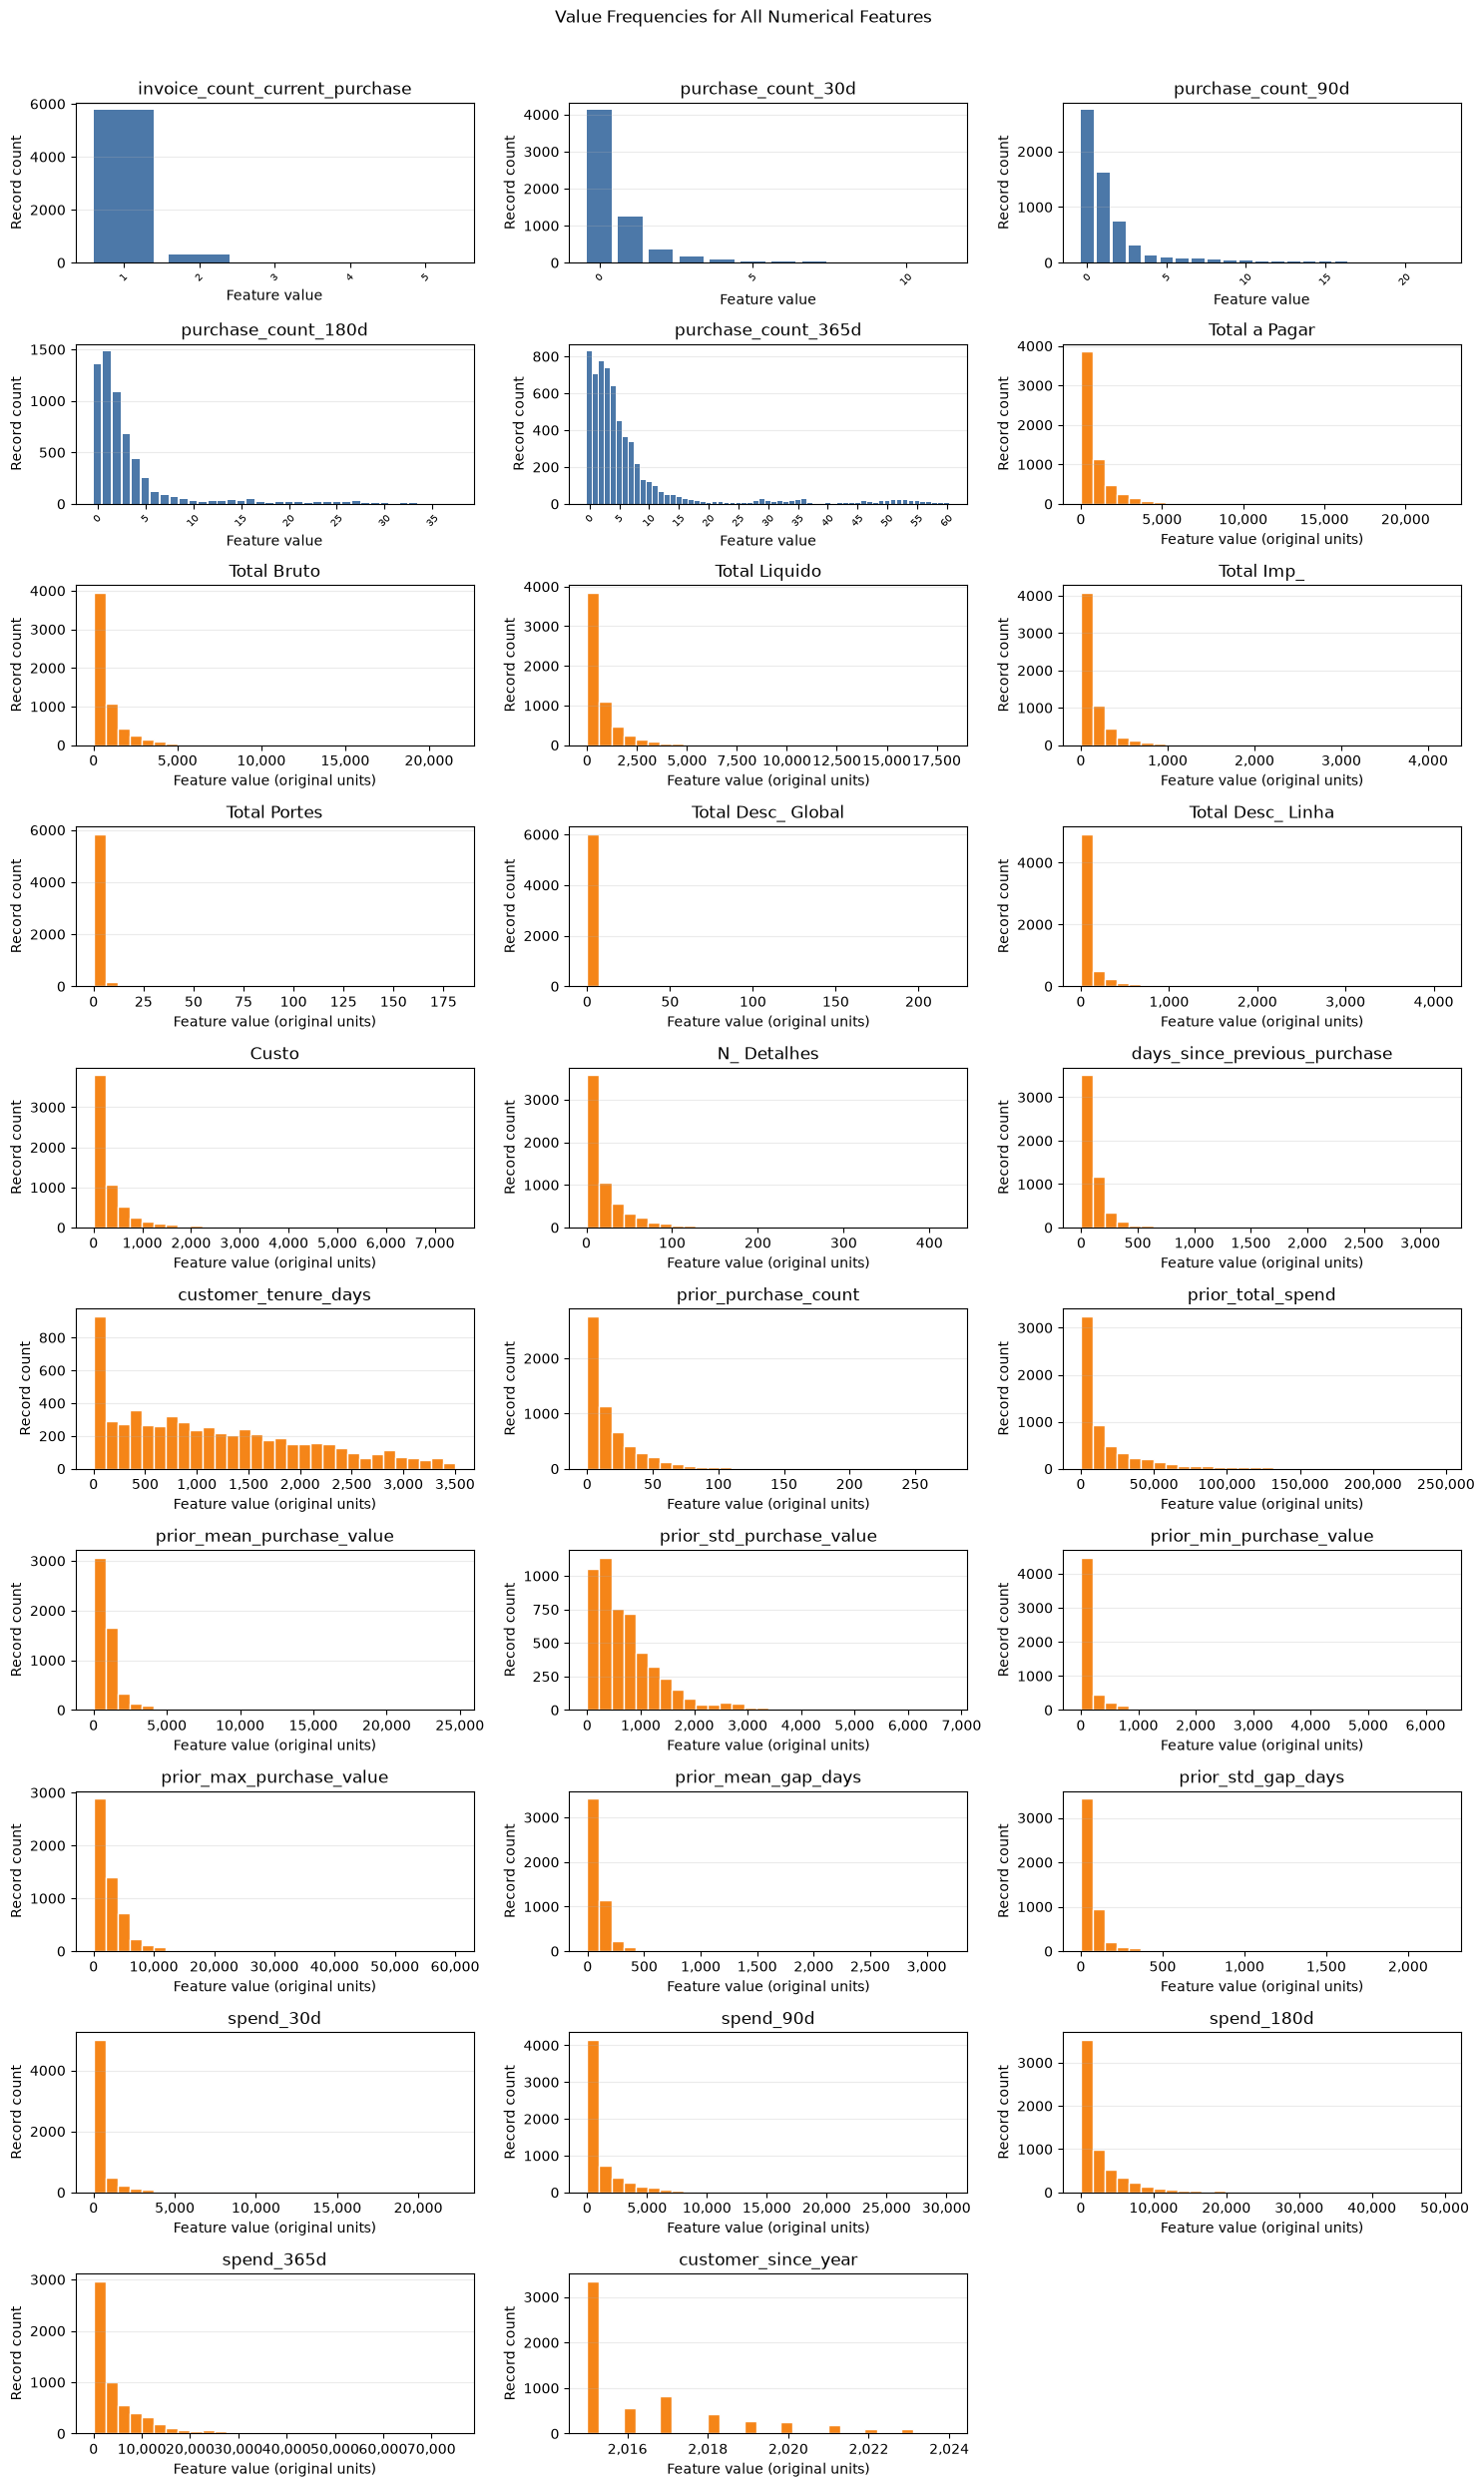

In [ ]:
frequency_features = [
    feature for feature in numerical_cols
    if feature.startswith("purchase_count_")
    or feature == "invoice_count_current_purchase"
]
continuous_features = [
    feature for feature in numerical_cols if feature not in frequency_features
]
plot_features = frequency_features + continuous_features
plot_columns = 3
plot_rows = (len(plot_features) + plot_columns - 1) // plot_columns
fig, axes = plt.subplots(
    plot_rows, plot_columns,
    figsize=(15, plot_rows * 2.5),
    squeeze=False,
)

# Discrete purchase counts: one bar per observed value.
for ax, feature in zip(axes.flat, frequency_features):
    counts = numerical_train[feature].value_counts().sort_index()
    ax.bar(counts.index, counts.values, color="#4C78A8")
    ax.set_title(feature)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Record count")
    ax.set_xticks(counts.index[::5] if feature.startswith("purchase_count_") else counts.index)
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    ax.grid(axis="y", alpha=0.25)

# Other numerical features: histogram bins show the number of records per range.
for ax, feature in zip(axes.flat[len(frequency_features):], continuous_features):
    values = numerical_train[feature].dropna()
    ax.hist(values, bins=30, color="#F58518", edgecolor="white")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title(feature)
    ax.set_xlabel("Feature value (original units)")
    ax.set_ylabel("Record count")
    ax.grid(axis="y", alpha=0.25)

for ax in axes.flat[len(plot_features):]:
    ax.set_visible(False)

fig.suptitle("Value Frequencies for All Numerical Features", y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

**Potential data-quality issue:** some purchase-history fields contain extreme values, including values near €1 billion. These could be data-entry or processing errors and can distort summaries and model fitting. Since the target is repeat purchase within 90 days, the model should learn typical customer behavior rather than be driven by a handful of implausible records. Investigate these rows and verify their source before deciding whether to correct or exclude them.

In [ ]:
outlier_counts = {}
for feature in numerical_cols:
    values = numerical_train[feature].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_mask = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    outlier_counts[feature] = int(outlier_mask.sum())

outlier_counts = pd.Series(outlier_counts, name="outlier_count").sort_values(
    ascending=False, kind="stable"
)
print(outlier_counts.to_string())

spend_30d                         1018
Total Portes                       985
Total Desc_ Linha                  774
purchase_count_180d                699
prior_min_purchase_value           645
spend_90d                          617
prior_total_spend                  582
Total Liquido                      541
Total a Pagar                      540
Total Bruto                        534
Custo                              502
Total Imp_                         499
prior_purchase_count               484
purchase_count_365d                483
spend_180d                         476
purchase_count_90d                 468
prior_std_gap_days                 440
customer_since_year                415
N_ Detalhes                        408
spend_365d                         407
purchase_count_30d                 368
prior_mean_gap_days                357
days_since_previous_purchase       354
prior_mean_purchase_value          345
invoice_count_current_purchase     331
prior_max_purchase_value 

## II.2 Imputation of remaining missing values
====missing work here=====
### **Unimputable Features**
(Rows with missing values were dropped above; no imputation fitted yet. Any imputation must be fit on the training fold only.)
Imputations for many of the features is extremely difficult, because many features are very interdependant and modifying a feature requires further modifications for all related features to avoid noise.

Ex:

Total a Pagar \& prior_mean_purchase_value \& prior_std_purchase_value

days_since_previous_purchase \& prior_mean_gap_days & prior_std_gap_days


### **Imputable Features**
Some features however can be imputable, for example, deriving the country or region using the city or postal code etc.

In [ ]:
# 1. Display missing counts before imputation
cols_to_check = ['city', 'municipality', 'postal_area', 'country_or_region']
print("--- Missing Values BEFORE ---")
print(train[cols_to_check].isna().sum())
print("\n")

# 2. Define the imputation function
def impute_geography_from_peers(df):
    df_clean = df.copy()
    
    # Define mapping relationships (source_column -> target_column_to_fill)
    mapping_pairs = [
        # --- 1. Fill highly specific locations first ---
        ('postal_area', 'city'),               # if city is missing but both share the same postal_area, impute to the same city
        
        # --- 2. Fill intermediate administrative zones using the (now more complete) cities ---
        ('city', 'municipality'),              # if municipality is missing but both share the same city, impute to the same municipality
        ('postal_area', 'municipality'),       # if municipality is missing but both share the same postal_area, impute to the same municipality
        
        # --- 3. Fill the broadest regions last, leveraging all the newly filled granular data ---
        ('city', 'country_or_region'),         # if country is missing but both share the same city, impute to the same country
        ('postal_area', 'country_or_region'),  # if country is missing but both share the same postal_area, impute to the same country
        ('municipality', 'country_or_region')  # if country is missing but both share the same municipality, impute to the same country
    ]
    
    for source_col, target_col in mapping_pairs:
        if source_col not in df_clean.columns or target_col not in df_clean.columns:
            continue
            
        missing_target = df_clean[target_col].isna()
        has_source = df_clean[source_col].notna()
        rows_to_fill = missing_target & has_source
        
        if not rows_to_fill.any():
            continue
            
        # Create lookup dictionary from rows where both columns are populated
        reference_data = df_clean.dropna(subset=[source_col, target_col])
        lookup_dict = reference_data.groupby(source_col)[target_col].first().to_dict()
        
        # Map the learned values to the missing rows
        df_clean.loc[rows_to_fill, target_col] = df_clean.loc[rows_to_fill, source_col].map(lookup_dict)
        
    return df_clean

# 3. Apply the function to the dataframe
train = impute_geography_from_peers(train)

# 4. Display missing counts after imputation to verify
print("--- Missing Values AFTER ---")
print(f"{train[cols_to_check].isna().sum()}\n if values are the same, restart the notebook")


--- Missing Values BEFORE ---
city                 1998
municipality          198
postal_area           256
country_or_region       0
dtype: int64


--- Missing Values AFTER ---
city                 361
municipality         195
postal_area          256
country_or_region      0
dtype: int64
 if values are the same, restart the notebook


Even tho we have fixed Country_or_region Feature, its value imbalance is too high to give us meaning

In [ ]:
train[train["city"].isna()][cols_to_check]

,city,municipality,postal_area,country_or_region
28,NaN,Municipality MU122: Council of Last Minute Edits,Postal area PA236: Hidden Sheet Sector,Country CT10: Land of The Final Version
46,NaN,Municipality MU31: Council of Last Minute Edits,Postal area PA121: Hidden Sheet Sector,Country CT10: Land of The Final Version
136,NaN,Municipality MU105: Council of Last Minute Edits,Postal area PA30: Hidden Sheet Sector,Country CT10: Land of The Final Version
152,NaN,Municipality MU69: Council of Last Minute Edits,Postal area PA89: Hidden Sheet Sector,Country CT10: Land of The Final Version
153,NaN,Municipality MU31: Council of Last Minute Edits,Postal area PA121: Hidden Sheet Sector,Country CT10: Land of The Final Version
...,...,...,...,...
6414,NaN,NaN,NaN,Country CT5: Land of The Final Version
6453,NaN,Municipality MU31: Council of Last Minute Edits,Postal area PA121: Hidden Sheet Sector,Country CT10: Land of The Final Version
6466,NaN,NaN,NaN,Country CT5: Land of The Final Version
6475,NaN,Municipality MU147: Council of Last Minute Edits,Postal area PA14: Hidden Sheet Sector,Country CT10: Land of The Final Version


## II.3 Categorical Encoding
Encode payment, salesperson, zone, transport, and warehouse.

====missing work here=====

## II.4 Feature Engineering
Derive new temporal or interaction features from purchase dates, historical gaps, and the random noise field.

====missing work here=====

## II.5 Scaling & Leakage Prevention
Fit all preprocessing (scaling, imputation, encoding) strictly on the training fold and apply to validation/test sets.

====missing work here=====

---
# III. Feature Selection Execution
## III.1 Filter Methods (Statistical Evaluation)
### Numerical vs. Numerical: Spearman (monotonic)
Checks monotonic correlation between features and with the label.

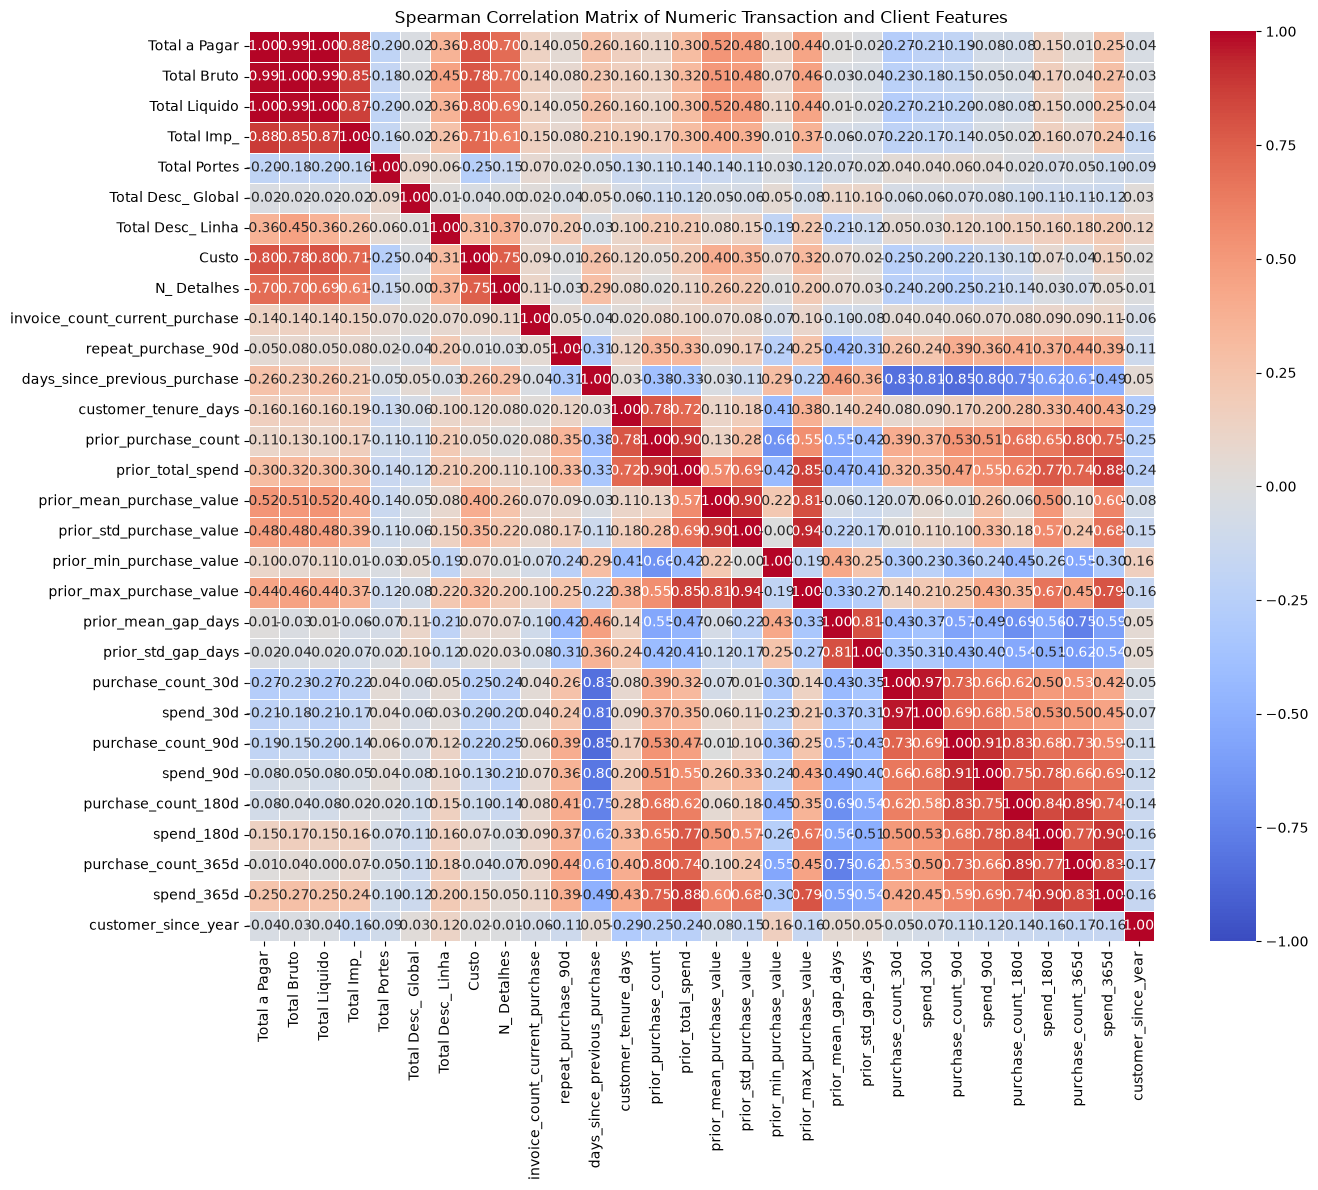

repeat_purchase_90d               1.000000
purchase_count_365d               0.437110
purchase_count_180d               0.405680
purchase_count_90d                0.392848
spend_365d                        0.390154
spend_180d                        0.371107
spend_90d                         0.361080
prior_purchase_count              0.348184
prior_total_spend                 0.333357
purchase_count_30d                0.261331
prior_max_purchase_value          0.253881
spend_30d                         0.237279
Total Desc_ Linha                 0.195887
prior_std_purchase_value          0.168845
customer_tenure_days              0.121877
prior_mean_purchase_value         0.089556
Total Imp_                        0.076295
Total Bruto                       0.076001
Total a Pagar                     0.050589
invoice_count_current_purchase    0.049312
Total Liquido                     0.047707
Total Portes                      0.019624
Custo                            -0.014713
N_ Detalhes

In [ ]:
numeric_features = train.select_dtypes(include="number")
numeric_features = numeric_features.loc[
    :, numeric_features.nunique(dropna=True) > 1
]
corr_matrix = numeric_features.corr(method='spearman')

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Spearman Correlation Matrix of Numeric Transaction and Client Features")
plt.tight_layout()
plt.show()

print(corr_matrix["repeat_purchase_90d"].sort_values(ascending=False))

### Numerical vs. Numerical: Pearson (linear)

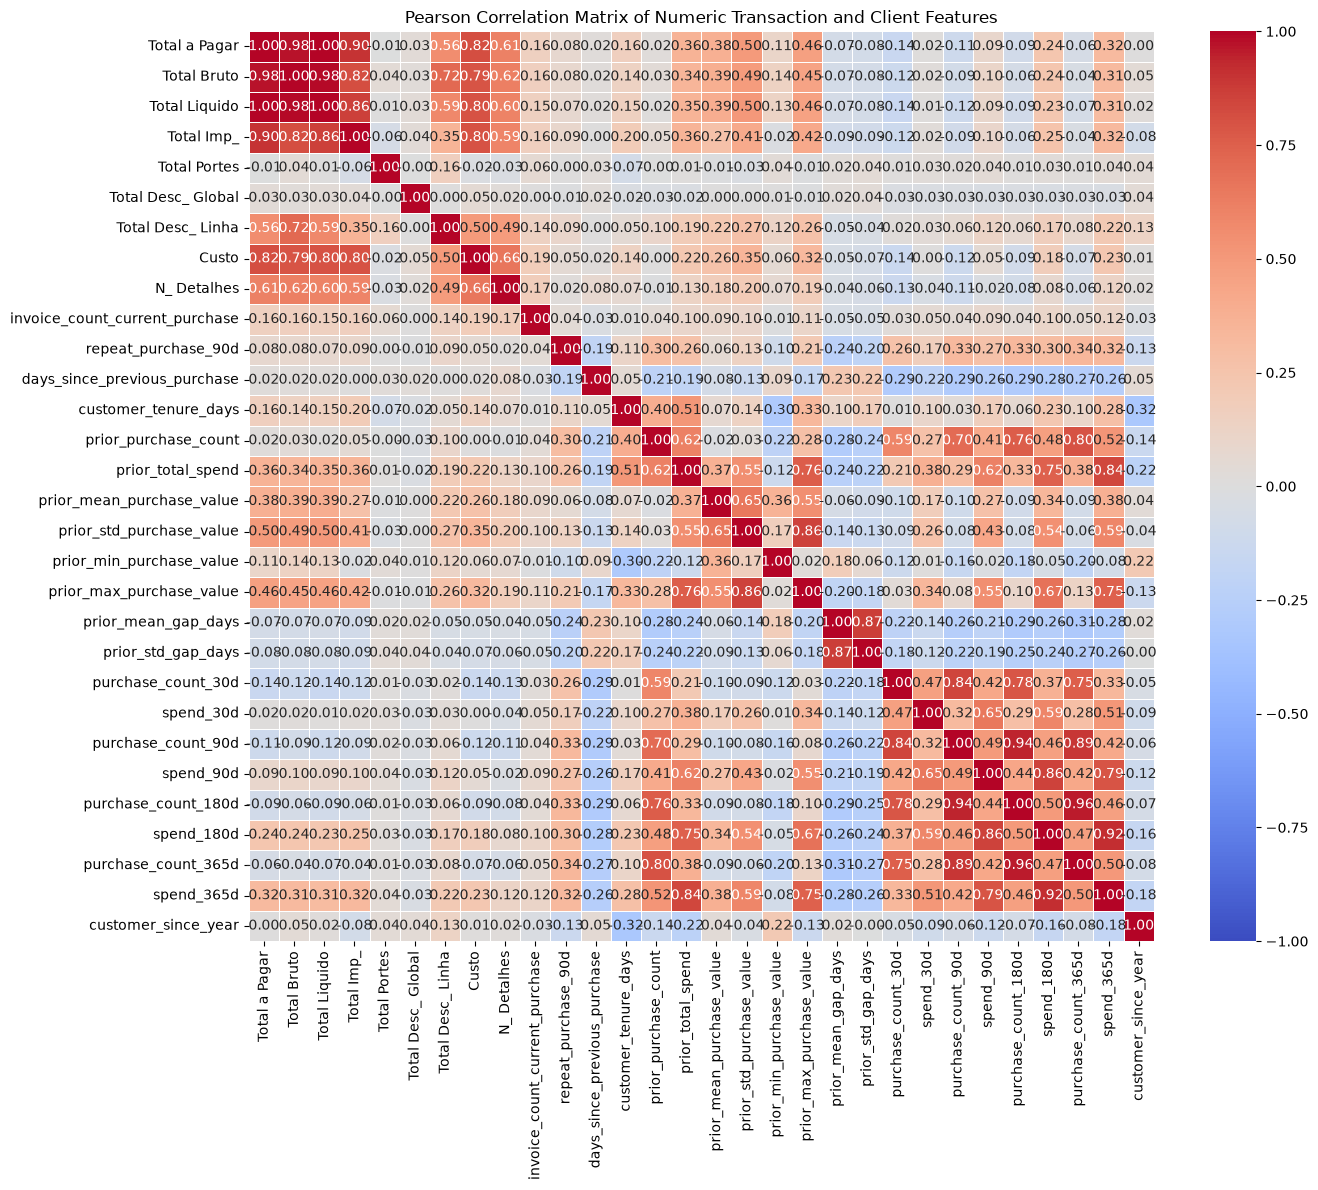

repeat_purchase_90d               1.000000
purchase_count_365d               0.339748
purchase_count_180d               0.332870
purchase_count_90d                0.326080
spend_365d                        0.320775
spend_180d                        0.300954
prior_purchase_count              0.300746
spend_90d                         0.267552
prior_total_spend                 0.263072
purchase_count_30d                0.260840
prior_max_purchase_value          0.205338
spend_30d                         0.166326
prior_std_purchase_value          0.133156
customer_tenure_days              0.109443
Total Desc_ Linha                 0.094782
Total Imp_                        0.090242
Total Bruto                       0.080787
Total a Pagar                     0.075075
Total Liquido                     0.070332
prior_mean_purchase_value         0.060792
Custo                             0.047481
invoice_count_current_purchase    0.040670
N_ Detalhes                       0.023110
Total Porte

In [ ]:
corr_matrix = numeric_features.corr(method="pearson")
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Pearson Correlation Matrix of Numeric Transaction and Client Features")
plt.tight_layout()
plt.show()

print(corr_matrix["repeat_purchase_90d"].sort_values(ascending=False))

Indications show some features have no correlation to any feature nor the label in both test including pearson and spearman, this gives insights on the first features to be discarded

### Numerical vs. Categorical: ANOVA
====missing work here=====

### Categorical vs. Categorical: Chi-Squared and Mutual Information / MIC
====missing work here=====

## III.2 Wrapper Methods (Search Optimization)
Recursive Feature Elimination (RFE), wrapped inside a 10-fold cross-validation loop to prevent selection bias.

====missing work here=====

## III.3 Embedded Methods (Penalization)
LASSO (L1) and Ridge (L2) regularization.

====missing work here=====

## III.4 Exclusions
Identifier-like variables (`ID`, `customer_id`) and `random_noise` were removed in Section II.1 (`columns_to_drop`), along with `customer_type` and `street` for excessive missingness. `commercial_zone` and `warehouse` are flagged as candidates for removal (near-constant).

====missing work here===== (final decision on `commercial_zone` / `warehouse`)

---
# IV. Model Selection & Assessment Strategy
## IV.1 Candidate Generation (Tribes)
Decision Trees / Random Forests, SVM, kNN, Naive Bayes, MLP.

====missing work here=====

/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_45239/867804320.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns
/Users/macbookpro/NovaWorkspace/MachineLearning/FinalProject/Project/ML_Group_22/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of p

--- MODEL METRICS ---
Accuracy:  0.7258
Precision: 0.7247
Recall:    0.7258
F1 Score:  0.7248

--- DETAILED REPORT ---
              precision    recall  f1-score   support

           0       0.70      0.66      0.68       533
           1       0.75      0.78      0.76       685

    accuracy                           0.73      1218
   macro avg       0.72      0.72      0.72      1218
weighted avg       0.72      0.73      0.72      1218

--- FEATURE IMPORTANCE ---
Top 5 STRONGEST Features:
                                         Feature  Coefficient
                            prior_purchase_count    -0.537322
                             purchase_count_365d     0.460103
     transport_method_Maybe Tomorrow Delivery 33     0.429736
commercial_region_Region RG24: We Will See Later     0.406242
                               company_name_Rare    -0.359684

Top 5 WEAKEST Features (L1 pushes these to 0.0):
                                                     Feature  Coefficient
     

/Users/macbookpro/NovaWorkspace/MachineLearning/FinalProject/Project/ML_Group_22/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/macbookpro/NovaWorkspace/MachineLearning/FinalProject/Project/ML_Group_22/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/macbookpro/NovaWorkspace/MachineLearning/FinalProject/Project/ML_Group_22/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 

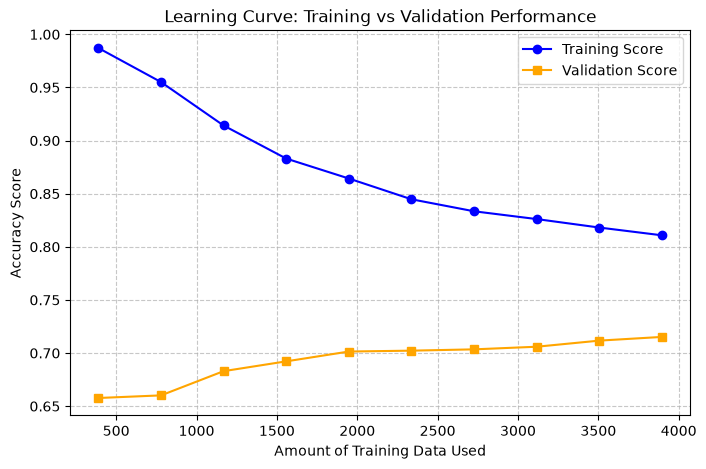

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1. Fill missing values
train_clean = train.fillna(0)

# 2. Rare Label Encoding
threshold = 0.001
categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
    frequencies = train_clean[col].value_counts(normalize=True)
    rare_categories = frequencies[frequencies < threshold].index
    train_clean[col] = train_clean[col].replace(rare_categories, 'Rare')

# 3. One-Hot Encoding
train_encoded = pd.get_dummies(train_clean, drop_first=True)

# 4. Separate features and target
X = train_encoded.drop('repeat_purchase_90d', axis=1)
y = train_encoded['repeat_purchase_90d']

# 5. Stratified Split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# --- FIX 1: Wrap in a Pipeline to scale inside cross-validation ---
pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty='l1', solver='saga', max_iter=2000, random_state=42, tol=1e-3) 
)

# 6. Fit Model
pipeline.fit(X_train, y_train)

# 7. Make predictions
predictions = pipeline.predict(X_val)

# 8. Metrics Printing
print("--- MODEL METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, predictions):.4f}")
print(f"Precision: {precision_score(y_val, predictions, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_val, predictions, average='weighted'):.4f}")
print(f"F1 Score:  {f1_score(y_val, predictions, average='weighted'):.4f}\n")

print("--- DETAILED REPORT ---")
print(classification_report(y_val, predictions))

# 9. Feature Impact Analysis
model = pipeline.named_steps['logisticregression']
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0], 
    'Impact_Strength': np.abs(model.coef_[0])
}).sort_values(by='Impact_Strength', ascending=False)

print("--- FEATURE IMPORTANCE ---")
print("Top 5 STRONGEST Features:")
print(coef_df.head(5)[['Feature', 'Coefficient']].to_string(index=False))

print("\nTop 5 WEAKEST Features (L1 pushes these to 0.0):")
print(coef_df.tail(5)[['Feature', 'Coefficient']].to_string(index=False))

# --- FIX 2: Pass pipeline into learning_curve so scaling happens inside each fold ---
train_sizes, train_scores, val_scores = learning_curve(
    pipeline, X_train, y_train, cv=5, scoring='accuracy', 
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, label='Training Score', marker='o', color='blue')
plt.plot(train_sizes, val_mean, label='Validation Score', marker='s', color='orange')
plt.title('Learning Curve: Training vs Validation Performance')
plt.xlabel('Amount of Training Data Used')
plt.ylabel('Accuracy Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_45239/1652014110.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns


Majority-class baseline accuracy: 0.5624

=== L1 Logistic Regression ===
Accuracy:  0.7110
Precision: 0.7141
Recall:    0.7110
F1 Score:  0.7119
ROC-AUC:   0.7758
              precision    recall  f1-score   support

           0       0.66      0.71      0.68       533
           1       0.76      0.72      0.74       685

    accuracy                           0.71      1218
   macro avg       0.71      0.71      0.71      1218
weighted avg       0.71      0.71      0.71      1218


=== L2 Logistic Regression ===
Accuracy:  0.7102
Precision: 0.7128
Recall:    0.7102
F1 Score:  0.7110
ROC-AUC:   0.7758
              precision    recall  f1-score   support

           0       0.66      0.70      0.68       533
           1       0.75      0.72      0.74       685

    accuracy                           0.71      1218
   macro avg       0.71      0.71      0.71      1218
weighted avg       0.71      0.71      0.71      1218


=== HistGradientBoosting (benchmark) ===
Accuracy:  0.6979
P

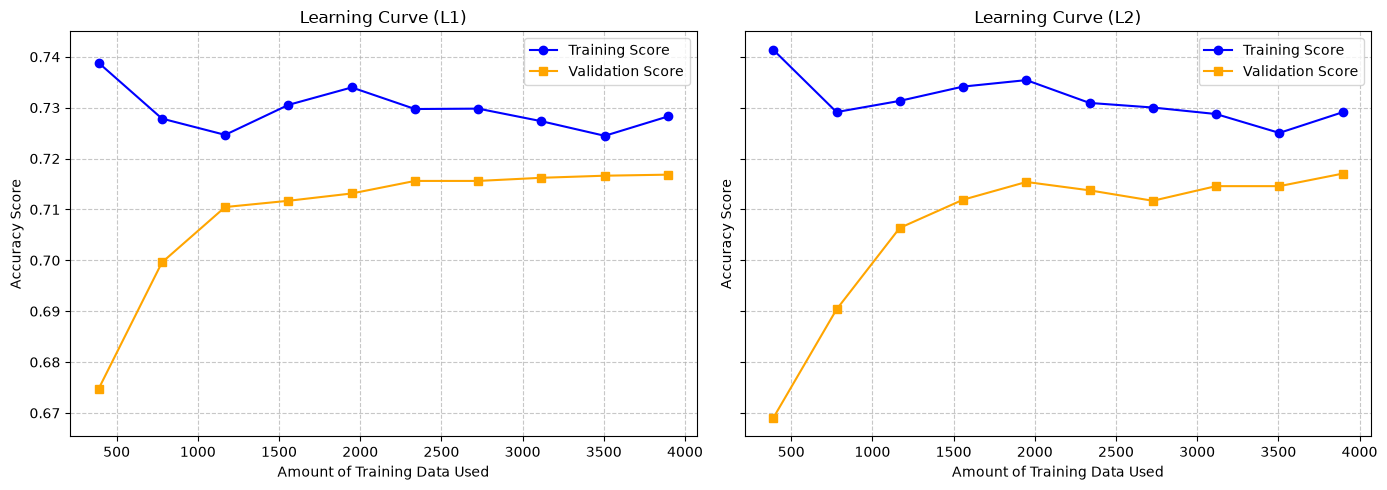

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)

# ------------------------------------------------------------------
# 1-4. Preprocessing (same as before)
# ------------------------------------------------------------------

train_clean.fillna(train_clean.mean(numeric_only=True), inplace=True)

threshold = 0.05  # try 0.01 too: 0.05 may be collapsing useful categories into 'Rare'
categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols:
    frequencies = train_clean[col].value_counts(normalize=True)
    rare_categories = frequencies[frequencies < threshold].index
    train_clean[col] = train_clean[col].replace(rare_categories, 'Rare')

train_encoded = pd.get_dummies(train_clean, drop_first=True)

X = train_encoded.drop('repeat_purchase_90d', axis=1)
y = train_encoded['repeat_purchase_90d']

# 5. Split (NO manual scaling here - the scaler lives inside the pipeline)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# ------------------------------------------------------------------
# 6. Models as pipelines (scaling happens inside, fit on train only)
# ------------------------------------------------------------------
l1_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(l1_ratio=1.0, solver='saga', max_iter=5000,
                       tol=1e-3, random_state=42)
)

# Default LogisticRegression is L2-regularised; lbfgs converges quickly on scaled data
l2_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver='lbfgs', max_iter=5000, random_state=42)
)

# Optional non-linear benchmark
gb_model = HistGradientBoostingClassifier(random_state=42)


def evaluate(name, model):
    model.fit(X_train, y_train)
    preds = model.predict(X_val)
    proba = model.predict_proba(X_val)[:, 1]
    print(f"\n=== {name} ===")
    print(f"Accuracy:  {accuracy_score(y_val, preds):.4f}")
    print(f"Precision: {precision_score(y_val, preds, average='weighted'):.4f}")
    print(f"Recall:    {recall_score(y_val, preds, average='weighted'):.4f}")
    print(f"F1 Score:  {f1_score(y_val, preds, average='weighted'):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_val, proba):.4f}")
    print(classification_report(y_val, preds))


baseline = y_val.value_counts(normalize=True).max()
print(f"Majority-class baseline accuracy: {baseline:.4f}")

evaluate("L1 Logistic Regression", l1_model)
evaluate("L2 Logistic Regression", l2_model)
evaluate("HistGradientBoosting (benchmark)", gb_model)

# ------------------------------------------------------------------
# 7. Feature importance: L1 vs L2, ALL features, side by side
# ------------------------------------------------------------------
l1_coef = l1_model[-1].coef_[0]
l2_coef = l2_model[-1].coef_[0]

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'L1_Coefficient': l1_coef,
    'L2_Coefficient': l2_coef,
    'L2_Impact_Strength': np.abs(l2_coef),
}).sort_values(by='L2_Impact_Strength', ascending=False)

print("\n--- FEATURE IMPORTANCE (ALL FEATURES, L1 vs L2) ---")
with pd.option_context('display.max_rows', None,
                       'display.max_colwidth', None,
                       'display.width', 250):
    print(importance_df.to_string(index=False))

print(f"\nFeatures zeroed out by L1: {(l1_coef == 0).sum()} of {len(l1_coef)}")

# ------------------------------------------------------------------
# 8. Learning curves (pipeline => scaling done per fold, no warnings)
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, model) in zip(axes, [("L1", l1_model), ("L2", l2_model)]):
    sizes, tr_scores, va_scores = learning_curve(
        model, X_train, y_train, cv=5, scoring='accuracy',
        train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
    )
    ax.plot(sizes, tr_scores.mean(axis=1), marker='o', color='blue', label='Training Score')
    ax.plot(sizes, va_scores.mean(axis=1), marker='s', color='orange', label='Validation Score')
    ax.set_title(f'Learning Curve ({name})')
    ax.set_xlabel('Amount of Training Data Used')
    ax.set_ylabel('Accuracy Score')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_45239/97703708.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns


--- MEAN CV ACCURACY (rows: l1_ratio, columns: C) ---
C         0.001   0.010   0.100   1.000   10.000
l1_ratio                                        
0.00      0.7107  0.7099  0.7125  0.7133  0.7140
0.25      0.6626  0.7133  0.7127  0.7138  0.7140
0.50      0.5626  0.7127  0.7123  0.7142  0.7138
0.75      0.5626  0.7080  0.7117  0.7144  0.7142
1.00      0.5626  0.7047  0.7107  0.7142  0.7140

Best: l1_ratio=0.75, C=1, CV accuracy=0.7144

--- VALIDATION METRICS (best model) ---
Accuracy:  0.7069
Precision: 0.7112
Recall:    0.7069
F1 Score:  0.7079
ROC-AUC:   0.7756

              precision    recall  f1-score   support

           0       0.65      0.71      0.68       533
           1       0.76      0.70      0.73       685

    accuracy                           0.71      1218
   macro avg       0.70      0.71      0.70      1218
weighted avg       0.71      0.71      0.71      1218


--- FEATURE IMPORTANCE (ALL FEATURES) ---
                                                     Fe

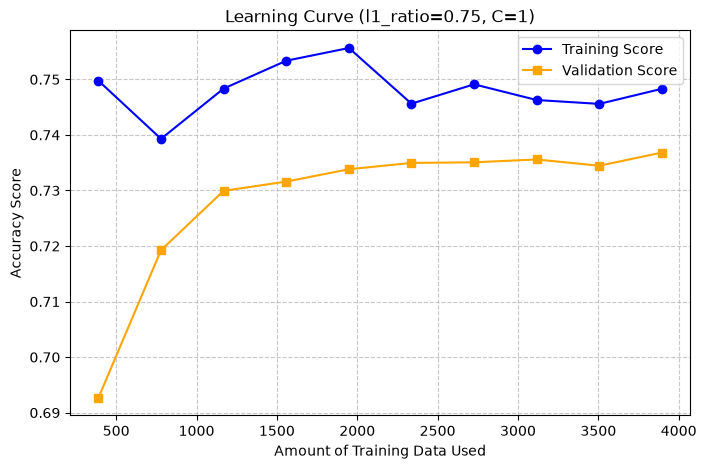

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, learning_curve, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)

# ------------------------------------------------------------------
# 1-4. Preprocessing & Filling Missing Values
# ------------------------------------------------------------------
train_clean = train.copy()
train_clean.fillna(train_clean.mean(numeric_only=True), inplace=True)
train_clean.fillna('Missing', inplace=True)

threshold = 0.05  # try 0.01 as well
categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols:
    frequencies = train_clean[col].value_counts(normalize=True)
    rare_categories = frequencies[frequencies < threshold].index
    train_clean[col] = train_clean[col].replace(rare_categories, 'Rare')

train_encoded = pd.get_dummies(train_clean, drop_first=True)

X = train_encoded.drop('repeat_purchase_90d', axis=1)
y = train_encoded['repeat_purchase_90d']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# ------------------------------------------------------------------
# 5. Sweep l1_ratio (0 = pure L2 ... 1 = pure L1) and C
#    saga supports the whole range; scaling is inside the pipeline
# ------------------------------------------------------------------
pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver='saga', max_iter=5000, tol=1e-3, random_state=42)
)

param_grid = {
    'logisticregression__l1_ratio': [0.0, 0.25, 0.5, 0.75, 1.0],
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, refit=True)
grid.fit(X_train, y_train)

# Results table: rows = l1_ratio, columns = C, values = mean CV accuracy
results = pd.DataFrame(grid.cv_results_)
table = results.pivot(index='param_logisticregression__l1_ratio',
                      columns='param_logisticregression__C',
                      values='mean_test_score')
table.index.name = 'l1_ratio'
table.columns.name = 'C'
print("--- MEAN CV ACCURACY (rows: l1_ratio, columns: C) ---")
print(table.round(4).to_string())

best_l1 = grid.best_params_['logisticregression__l1_ratio']
best_C = grid.best_params_['logisticregression__C']
print(f"\nBest: l1_ratio={best_l1}, C={best_C}, CV accuracy={grid.best_score_:.4f}")

# ------------------------------------------------------------------
# 6. Validation metrics for the best model
# ------------------------------------------------------------------
best_model = grid.best_estimator_
preds = best_model.predict(X_val)
proba = best_model.predict_proba(X_val)[:, 1]

print("\n--- VALIDATION METRICS (best model) ---")
print(f"Accuracy:  {accuracy_score(y_val, preds):.4f}")
print(f"Precision: {precision_score(y_val, preds, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_val, preds, average='weighted'):.4f}")
print(f"F1 Score:  {f1_score(y_val, preds, average='weighted'):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, proba):.4f}\n")
print(classification_report(y_val, preds))

# ------------------------------------------------------------------
# 7. Feature importance for ALL features:
#    pure L2 (0.0), best mix, pure L1 (1.0), all at the best C
# ------------------------------------------------------------------
def fit_coefs(l1_ratio):
    m = make_pipeline(
        StandardScaler(),
        LogisticRegression(solver='saga', max_iter=5000, tol=1e-3,
                           C=best_C, l1_ratio=l1_ratio, random_state=42)
    )
    m.fit(X_train, y_train)
    return m[-1].coef_[0]

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'L2_only (0.0)': fit_coefs(0.0),
    f'Best (l1_ratio={best_l1})': best_model[-1].coef_[0],
    'L1_only (1.0)': fit_coefs(1.0),
})
best_col = f'Best (l1_ratio={best_l1})'
importance_df['Best_Impact_Strength'] = importance_df[best_col].abs()
importance_df = importance_df.sort_values('Best_Impact_Strength', ascending=False)

print("\n--- FEATURE IMPORTANCE (ALL FEATURES) ---")
with pd.option_context('display.max_rows', None,
                       'display.max_colwidth', None,
                       'display.width', 250):
    print(importance_df.to_string(index=False))

n_zero = (importance_df[best_col] == 0).sum()
print(f"\nFeatures zeroed out by the best model: {n_zero} of {len(importance_df)}")

# ------------------------------------------------------------------
# 8. Learning curve for the best model
# ------------------------------------------------------------------
sizes, tr_scores, va_scores = learning_curve(
    best_model, X_train, y_train, cv=5, scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)
plt.figure(figsize=(8, 5))
plt.plot(sizes, tr_scores.mean(axis=1), marker='o', color='blue', label='Training Score')
plt.plot(sizes, va_scores.mean(axis=1), marker='s', color='orange', label='Validation Score')
plt.title(f'Learning Curve (l1_ratio={best_l1}, C={best_C})')
plt.xlabel('Amount of Training Data Used')
plt.ylabel('Accuracy Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_45239/2422226911.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns


--- MEAN CV ACCURACY (rows: l1_ratio, columns: C) ---
C         0.001   0.010   0.100   1.000   10.000
l1_ratio                                        
0.00      0.7107  0.7099  0.7125  0.7133  0.7140
0.25      0.6626  0.7133  0.7127  0.7138  0.7140
0.50      0.5626  0.7127  0.7123  0.7142  0.7138
0.75      0.5626  0.7080  0.7117  0.7144  0.7142
1.00      0.5626  0.7047  0.7107  0.7142  0.7140

Best: l1_ratio=0.75, C=1, CV accuracy=0.7144

--- VALIDATION METRICS (best model) ---
Accuracy:  0.7069
Precision: 0.7112
Recall:    0.7069
F1 Score:  0.7079
ROC-AUC:   0.7756

              precision    recall  f1-score   support

           0       0.65      0.71      0.68       533
           1       0.76      0.70      0.73       685

    accuracy                           0.71      1218
   macro avg       0.70      0.71      0.70      1218
weighted avg       0.71      0.71      0.71      1218


--- FEATURE IMPORTANCE (ALL FEATURES) ---
                                                     Fe

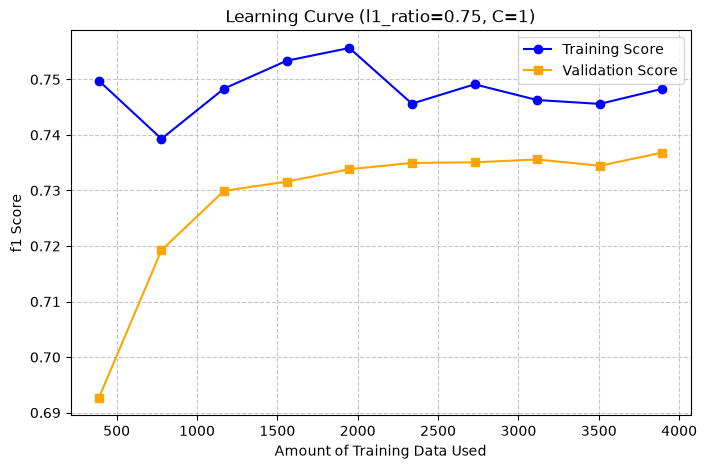

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, learning_curve, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)

# ------------------------------------------------------------------
# 1-4. Preprocessing (same as before)
# ------------------------------------------------------------------
train_clean.fillna(train_clean.mean(numeric_only=True), inplace=True)

threshold = 0.05  # try 0.01 as well
categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols:
    frequencies = train_clean[col].value_counts(normalize=True)
    rare_categories = frequencies[frequencies < threshold].index
    train_clean[col] = train_clean[col].replace(rare_categories, 'Rare')

train_encoded = pd.get_dummies(train_clean, drop_first=True)

X = train_encoded.drop('repeat_purchase_90d', axis=1)
y = train_encoded['repeat_purchase_90d']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# ------------------------------------------------------------------
# 5. Sweep l1_ratio (0 = pure L2 ... 1 = pure L1) and C
#    saga supports the whole range; scaling is inside the pipeline
# ------------------------------------------------------------------
pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver='saga', max_iter=5000, tol=1e-3, random_state=42)
)

param_grid = {
    'logisticregression__l1_ratio': [0.0, 0.25, 0.5, 0.75, 1.0],
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, refit=True)
grid.fit(X_train, y_train)

# Results table: rows = l1_ratio, columns = C, values = mean CV accuracy
results = pd.DataFrame(grid.cv_results_)
table = results.pivot(index='param_logisticregression__l1_ratio',
                      columns='param_logisticregression__C',
                      values='mean_test_score')
table.index.name = 'l1_ratio'
table.columns.name = 'C'
print("--- MEAN CV ACCURACY (rows: l1_ratio, columns: C) ---")
print(table.round(4).to_string())

best_l1 = grid.best_params_['logisticregression__l1_ratio']
best_C = grid.best_params_['logisticregression__C']
print(f"\nBest: l1_ratio={best_l1}, C={best_C}, CV accuracy={grid.best_score_:.4f}")

# ------------------------------------------------------------------
# 6. Validation metrics for the best model
# ------------------------------------------------------------------
best_model = grid.best_estimator_
preds = best_model.predict(X_val)
proba = best_model.predict_proba(X_val)[:, 1]

print("\n--- VALIDATION METRICS (best model) ---")
print(f"Accuracy:  {accuracy_score(y_val, preds):.4f}")
print(f"Precision: {precision_score(y_val, preds, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_val, preds, average='weighted'):.4f}")
print(f"F1 Score:  {f1_score(y_val, preds, average='weighted'):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, proba):.4f}\n")
print(classification_report(y_val, preds))

# ------------------------------------------------------------------
# 7. Feature importance for ALL features:
#    pure L2 (0.0), best mix, pure L1 (1.0), all at the best C
# ------------------------------------------------------------------
def fit_coefs(l1_ratio):
    m = make_pipeline(
        StandardScaler(),
        LogisticRegression(solver='saga', max_iter=5000, tol=1e-3,
                           C=best_C, l1_ratio=l1_ratio, random_state=42)
    )
    m.fit(X_train, y_train)
    return m[-1].coef_[0]

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'L2_only (0.0)': fit_coefs(0.0),
    f'Best (l1_ratio={best_l1})': best_model[-1].coef_[0],
    'L1_only (1.0)': fit_coefs(1.0),
})
best_col = f'Best (l1_ratio={best_l1})'
importance_df['Best_Impact_Strength'] = importance_df[best_col].abs()
importance_df = importance_df.sort_values('Best_Impact_Strength', ascending=False)

print("\n--- FEATURE IMPORTANCE (ALL FEATURES) ---")
with pd.option_context('display.max_rows', None,
                       'display.max_colwidth', None,
                       'display.width', 250):
    print(importance_df.to_string(index=False))

n_zero = (importance_df[best_col] == 0).sum()
print(f"\nFeatures zeroed out by the best model: {n_zero} of {len(importance_df)}")

# ------------------------------------------------------------------
# 8. Learning curve for the best model
# ------------------------------------------------------------------
sizes, tr_scores, va_scores = learning_curve(
    best_model, X_train, y_train, cv=5, scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)
plt.figure(figsize=(8, 5))
plt.plot(sizes, tr_scores.mean(axis=1), marker='o', color='blue', label='Training Score')
plt.plot(sizes, va_scores.mean(axis=1), marker='s', color='orange', label='Validation Score')
plt.title(f'Learning Curve (l1_ratio={best_l1}, C={best_C})')
plt.xlabel('Amount of Training Data Used')
plt.ylabel('f1 Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_45239/1813577449.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns


HGB best CV F1 Score: 0.7466


/Users/macbookpro/NovaWorkspace/MachineLearning/FinalProject/Project/ML_Group_22/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/macbookpro/NovaWorkspace/MachineLearning/FinalProject/Project/ML_Group_22/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/macbookpro/NovaWorkspace/MachineLearning/FinalProject/Project/ML_Group_22/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make

RF best CV F1 Score: 0.7428

--- MODEL COMPARISON (Optimized for F1) ---
               Model  Optimal Threshold  F1 (Class 1)  Accuracy  Precision  Recall  ROC-AUC
HistGradientBoosting             0.3589        0.7654    0.6995     0.6823  0.8715   0.7946
       Logistic (L2)             0.4435        0.7529    0.7069     0.7158  0.7942   0.7790
       Random Forest             0.3770        0.7502    0.6773     0.6644  0.8613   0.7715

Best Model by F1 Score: HistGradientBoosting (Threshold: 0.3589)

              precision    recall  f1-score   support

           0       0.74      0.48      0.58       533
           1       0.68      0.87      0.77       685

    accuracy                           0.70      1218
   macro avg       0.71      0.67      0.67      1218
weighted avg       0.71      0.70      0.69      1218


--- FEATURE IMPORTANCE: HistGradientBoosting (Permutation, F1-Scoring) ---
                                                      Feature  Importance_Mean  Importanc

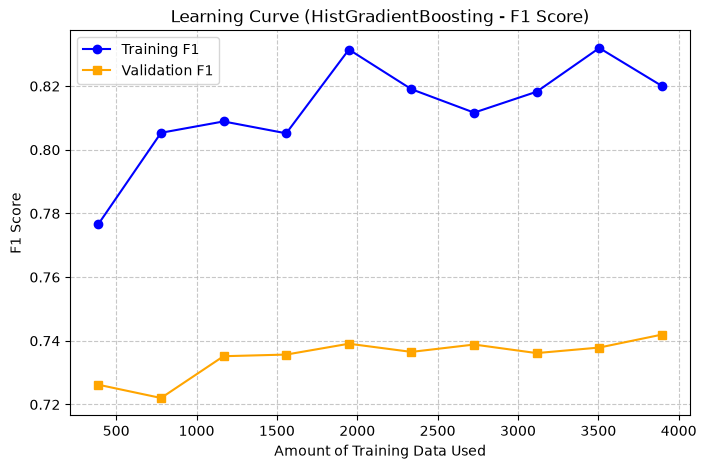

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint
from sklearn.model_selection import (train_test_split, learning_curve,
                                     RandomizedSearchCV, StratifiedKFold)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             precision_recall_curve)

# ------------------------------------------------------------------
# 1-4. Preprocessing
# ------------------------------------------------------------------
train_clean = train.fillna(0)

threshold = 0.01
categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols:
    frequencies = train_clean[col].value_counts(normalize=True)
    rare_categories = frequencies[frequencies < threshold].index
    train_clean[col] = train_clean[col].replace(rare_categories, 'Rare')

train_encoded = pd.get_dummies(train_clean, drop_first=True)

X = train_encoded.drop('repeat_purchase_90d', axis=1)
y = train_encoded['repeat_purchase_90d']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ------------------------------------------------------------------
# 5. Tune HistGradientBoosting (Optimized for F1)
# ------------------------------------------------------------------
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(early_stopping=True, validation_fraction=0.15,
                                   n_iter_no_change=20, random_state=42),
    param_distributions={
        'learning_rate': loguniform(0.01, 0.3),
        'max_iter': randint(100, 600),
        'max_leaf_nodes': randint(4, 40),
        'min_samples_leaf': randint(10, 100),
        'l2_regularization': loguniform(1e-3, 10),
    },
    n_iter=40, cv=cv, scoring='f1', n_jobs=-1, random_state=42, refit=True
)
hgb_search.fit(X_train, y_train)
print(f"HGB best CV F1 Score: {hgb_search.best_score_:.4f}")
hgb = hgb_search.best_estimator_

# ------------------------------------------------------------------
# 6. Random Forest & Logistic Baseline (Optimized for F1)
# ------------------------------------------------------------------
rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=42),
    param_distributions={
        'n_estimators': randint(200, 600),
        'max_depth': randint(4, 12),
        'min_samples_leaf': randint(20, 50),
        'max_features': ['sqrt', 0.3, 0.5],
    },
    n_iter=20, cv=cv, scoring='f1', n_jobs=-1, random_state=42, refit=True
)
rf_search.fit(X_train, y_train)
print(f"RF best CV F1 Score: {rf_search.best_score_:.4f}")
rf = rf_search.best_estimator_

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver='lbfgs', max_iter=500, random_state=42)
).fit(X_train, y_train)

# ------------------------------------------------------------------
# 7. Threshold Optimization & Side-by-side comparison (F1 Prioritized)
# ------------------------------------------------------------------
models = {'Logistic (L2)': logreg, 'Random Forest': rf, 'HistGradientBoosting': hgb}
rows = []

for name, m in models.items():
    pr = m.predict_proba(X_val)[:, 1]
    
    # Calculate precision-recall curve to find the threshold that maximizes F1
    precisions, recalls, thresholds = precision_recall_curve(y_val, pr)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores[:-1])
    thresh = thresholds[best_idx]
    max_f1 = f1_scores[best_idx]
    
    p = (pr >= thresh).astype(int)
    
    rows.append({
        'Model': name,
        'Optimal Threshold': thresh,
        'F1 (Class 1)': max_f1,
        'Accuracy': accuracy_score(y_val, p),
        'Precision': precision_score(y_val, p, zero_division=0),
        'Recall': recall_score(y_val, p, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, pr),
    })

comparison_df = pd.DataFrame(rows).sort_values(by='F1 (Class 1)', ascending=False)
print("\n--- MODEL COMPARISON (Optimized for F1) ---")
print(comparison_df.round(4).to_string(index=False))

best_name = comparison_df.iloc[0]['Model']
best_threshold = comparison_df.iloc[0]['Optimal Threshold']
best_model = models[best_name]

print(f"\nBest Model by F1 Score: {best_name} (Threshold: {best_threshold:.4f})\n")

y_val_prob = best_model.predict_proba(X_val)[:, 1]
y_val_pred_opt = (y_val_prob >= best_threshold).astype(int)
print(classification_report(y_val, y_val_pred_opt))

# ------------------------------------------------------------------
# 8. Feature Importance (Permutation using F1-Scoring)
# ------------------------------------------------------------------
perm = permutation_importance(best_model, X_val, y_val, scoring='f1',
                              n_repeats=10, random_state=42, n_jobs=-1)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance_Mean': perm.importances_mean,
    'Importance_Std': perm.importances_std,
}).sort_values('Importance_Mean', ascending=False)

print(f"\n--- FEATURE IMPORTANCE: {best_name} (Permutation, F1-Scoring) ---")
with pd.option_context('display.max_rows', None,
                       'display.max_colwidth', None,
                       'display.width', 250):
    print(importance_df.to_string(index=False))

# ------------------------------------------------------------------
# 9. Learning Curve (F1 Metric)
# ------------------------------------------------------------------
sizes, tr_scores, va_scores = learning_curve(
    best_model, X_train, y_train, cv=5, scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)
plt.figure(figsize=(8, 5))
plt.plot(sizes, tr_scores.mean(axis=1), marker='o', color='blue', label='Training F1')
plt.plot(sizes, va_scores.mean(axis=1), marker='s', color='orange', label='Validation F1')
plt.title(f'Learning Curve ({best_name} - F1 Score)')
plt.xlabel('Amount of Training Data Used')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_45239/3587720169.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns


HGB best CV accuracy: 0.7240
HGB best params: {'l2_regularization': np.float64(0.162769247720609), 'learning_rate': np.float64(0.07507320006113874), 'max_iter': 538, 'max_leaf_nodes': 14, 'min_samples_leaf': 65}

RF best CV accuracy: 0.7248
RF best params: {'max_depth': 19, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 513}

--- MODEL COMPARISON (validation set) ---
               Model  Accuracy  Precision  Recall     F1  ROC-AUC
       Logistic (L2)    0.7053     0.7060  0.7053 0.7056   0.7788
       Random Forest    0.7135     0.7151  0.7135 0.7140   0.7891
HistGradientBoosting    0.7184     0.7204  0.7184 0.7190   0.7935

Best by ROC-AUC: HistGradientBoosting

              precision    recall  f1-score   support

           0       0.67      0.70      0.69       533
           1       0.76      0.73      0.74       685

    accuracy                           0.72      1218
   macro avg       0.71      0.72      0.72      1218
weighted avg       0.72      0.72     

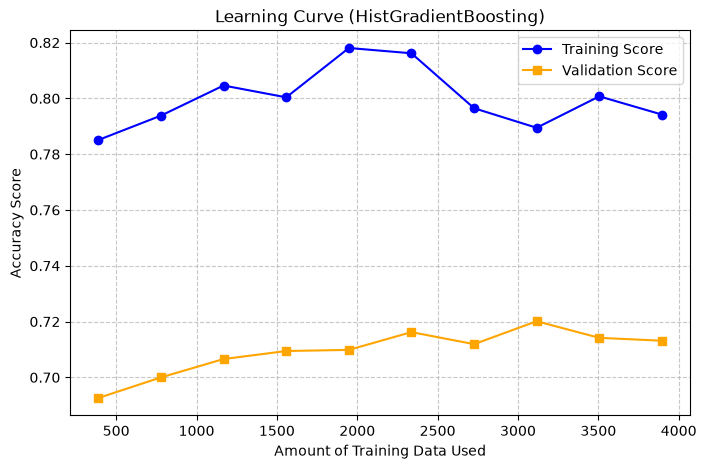

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint
from sklearn.model_selection import (train_test_split, learning_curve,
                                     RandomizedSearchCV, StratifiedKFold)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)

# ------------------------------------------------------------------
# 1-4. Preprocessing
#      Trees do not need scaling, and can handle a lower rare-label
#      threshold, so 0.01 keeps more geographic detail.
# ------------------------------------------------------------------
train_clean = train.fillna(0)

# --- NEW: Convert cumulative overlapping features into non-overlapping windows ---
# For Spend
if 'spend_365d' in train_clean.columns:
    train_clean['spend_181_365d'] = train_clean['spend_365d'] - train_clean['spend_180d']
    train_clean['spend_91_180d'] = train_clean['spend_180d'] - train_clean['spend_90d']
    train_clean['spend_31_90d'] = train_clean['spend_90d'] - train_clean['spend_30d']
    # We keep spend_30d as the base 0-30 days bucket and drop the cumulative ones
    train_clean = train_clean.drop(columns=['spend_365d', 'spend_180d', 'spend_90d'])

# For Purchase Count
if 'purchase_count_365d' in train_clean.columns:
    train_clean['purchase_count_181_365d'] = train_clean['purchase_count_365d'] - train_clean['purchase_count_180d']
    train_clean['purchase_count_91_180d'] = train_clean['purchase_count_180d'] - train_clean['purchase_count_90d']
    train_clean['purchase_count_31_90d'] = train_clean['purchase_count_90d'] - train_clean['purchase_count_30d']
    # We keep purchase_count_30d as the base 0-30 days bucket and drop the cumulative ones
    train_clean = train_clean.drop(columns=['purchase_count_365d', 'purchase_count_180d', 'purchase_count_90d'])
# -------------------------------------------------------------------------------

threshold = 0.01
categorical_cols = train_clean.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols:
    frequencies = train_clean[col].value_counts(normalize=True)
    rare_categories = frequencies[frequencies < threshold].index
    train_clean[col] = train_clean[col].replace(rare_categories, 'Rare')

train_encoded = pd.get_dummies(train_clean, drop_first=True)

X = train_encoded.drop('repeat_purchase_90d', axis=1)
y = train_encoded['repeat_purchase_90d']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ------------------------------------------------------------------
# 5. Tune HistGradientBoosting (randomized search = faster than a full grid)
# ------------------------------------------------------------------
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(early_stopping=True, validation_fraction=0.15,
                                   n_iter_no_change=20, random_state=42),
    param_distributions={
        'learning_rate': loguniform(0.01, 0.3),
        'max_iter': randint(100, 600),
        'max_leaf_nodes': randint(4, 40),
        'min_samples_leaf': randint(10, 100),
        'l2_regularization': loguniform(1e-3, 10),
    },
    n_iter=40, cv=cv, scoring='accuracy', n_jobs=-1, random_state=42, refit=True
)
hgb_search.fit(X_train, y_train)
print(f"HGB best CV accuracy: {hgb_search.best_score_:.4f}")
print(f"HGB best params: {hgb_search.best_params_}\n")
hgb = hgb_search.best_estimator_

# ------------------------------------------------------------------
# 6. Random forest (second opinion) and logistic baseline (for comparison)
# ------------------------------------------------------------------
rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=42),
    param_distributions={
        'n_estimators': randint(200, 600),
        'max_depth': randint(4, 20),
        'min_samples_leaf': randint(2, 30),
        'max_features': ['sqrt', 0.3, 0.5],
    },
    n_iter=20, cv=cv, scoring='accuracy', n_jobs=1, random_state=42, refit=True
)
rf_search.fit(X_train, y_train)
print(f"RF best CV accuracy: {rf_search.best_score_:.4f}")
print(f"RF best params: {rf_search.best_params_}\n")
rf = rf_search.best_estimator_

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver='lbfgs', max_iter=5000, random_state=42)
).fit(X_train, y_train)

# ------------------------------------------------------------------
# 7. Side-by-side comparison on the validation set
# ------------------------------------------------------------------
models = {'Logistic (L2)': logreg, 'Random Forest': rf, 'HistGradientBoosting': hgb}
rows = []
for name, m in models.items():
    p = m.predict(X_val)
    pr = m.predict_proba(X_val)[:, 1]
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, p),
        'Precision': precision_score(y_val, p, average='weighted'),
        'Recall': recall_score(y_val, p, average='weighted'),
        'F1': f1_score(y_val, p, average='weighted'),
        'ROC-AUC': roc_auc_score(y_val, pr),
    })
print("--- MODEL COMPARISON (validation set) ---")
print(pd.DataFrame(rows).round(4).to_string(index=False))

best_name = max(rows, key=lambda r: r['ROC-AUC'])['Model']
best_model = models[best_name]
print(f"\nBest by ROC-AUC: {best_name}\n")
print(classification_report(y_val, best_model.predict(X_val)))

# ------------------------------------------------------------------
# 8. Feature importance for ALL features (permutation importance)
#    Trees have no coefficients; permutation importance measures how much
#    validation accuracy drops when a feature is shuffled.
# ------------------------------------------------------------------
perm = permutation_importance(best_model, X_val, y_val, scoring='accuracy',
                              n_repeats=10, random_state=42, n_jobs=-1)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance_Mean': perm.importances_mean,
    'Importance_Std': perm.importances_std,
}).sort_values('Importance_Mean', ascending=False)

print(f"--- FEATURE IMPORTANCE: {best_name} (ALL FEATURES, permutation) ---")
with pd.option_context('display.max_rows', None,
                       'display.max_colwidth', None,
                       'display.width', 250):
    print(importance_df.to_string(index=False))

# ------------------------------------------------------------------
# 9. Learning curve for the best model
# ------------------------------------------------------------------
sizes, tr_scores, va_scores = learning_curve(
    best_model, X_train, y_train, cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)
plt.figure(figsize=(8, 5))
plt.plot(sizes, tr_scores.mean(axis=1), marker='o', color='blue', label='Training Score')
plt.plot(sizes, va_scores.mean(axis=1), marker='s', color='orange', label='Validation Score')
plt.title(f'Learning Curve ({best_name})')
plt.xlabel('Amount of Training Data Used')
plt.ylabel('Accuracy Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
from sklearn.metrics import precision_recall_curve

# 1. Get the raw probabilities for the positive class
y_pred_prob = best_model.predict_proba(X_val)[:, 1]

# 2. Calculate precision, recall, and thresholds at every possible cutoff
precisions, recalls, thresholds = precision_recall_curve(y_val, y_pred_prob)

# 3. Calculate the F1 score for every threshold
# (Adding 1e-10 prevents division by zero warnings)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)

# 4. Find the index of the highest F1 score
# Note: precision_recall_curve returns one less threshold than precision/recall values,
# so we slice off the last F1 score to make the arrays align.
best_index = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print(f"Optimal Threshold for F1 Score: {best_threshold:.4f}")
print(f"Maximum F1 Score: {best_f1:.4f}\n")

# 5. Apply this new optimal threshold to your validation predictions
y_pred_best_f1 = (y_pred_prob >= best_threshold).astype(int)

print(f"--- Classification Report (Threshold = {best_threshold:.4f}) ---")
print(classification_report(y_val, y_pred_best_f1))

Optimal Threshold for F1 Score: 0.3369
Maximum F1 Score: 0.7639

--- Classification Report (Threshold = 0.3369) ---
              precision    recall  f1-score   support

           0       0.75      0.45      0.56       533
           1       0.67      0.88      0.76       685

    accuracy                           0.69      1218
   macro avg       0.71      0.67      0.66      1218
weighted avg       0.71      0.69      0.68      1218



/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_45239/2272061862.py:54: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(include=['object']).columns


HGB Best CV F1-Score: 0.7530
HGB Best Params: {'l2_regularization': np.float64(0.26926469100861794), 'learning_rate': np.float64(0.0178601378893971), 'max_iter': 266, 'max_leaf_nodes': 21, 'min_samples_leaf': 397}

Optimal Threshold for F1 Score: 0.3914
Maximum Validation F1 Score: 0.7708

ROC-AUC: 0.7951

--- CLASSIFICATION REPORT (Threshold = 0.3914) ---
              precision    recall  f1-score   support

           0       0.74      0.53      0.62       533
           1       0.70      0.85      0.77       685

    accuracy                           0.71      1218
   macro avg       0.72      0.69      0.70      1218
weighted avg       0.72      0.71      0.71      1218

--- FEATURE IMPORTANCE (Permutation, F1-Scoring) ---
                       Feature  Importance_Mean  Importance_Std
       purchase_count_181_365d         0.017277        0.008644
             commercial_region         0.009114        0.004524
                purchase_month         0.008145        0.002571
     

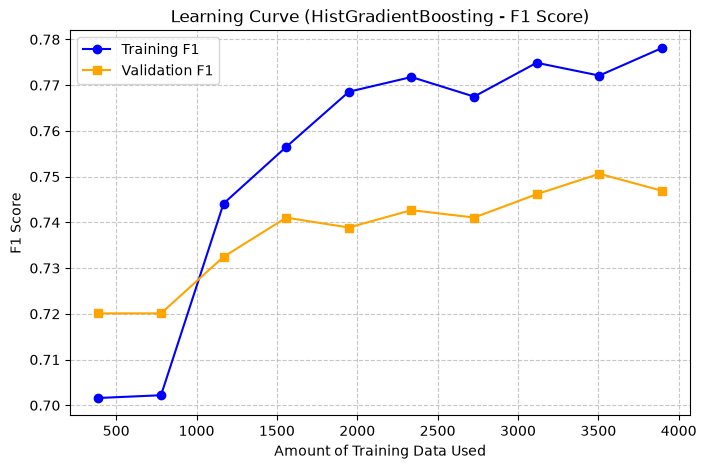

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint
from sklearn.model_selection import (train_test_split, learning_curve,
                                     RandomizedSearchCV, StratifiedKFold)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, precision_recall_curve, roc_auc_score

# ------------------------------------------------------------------
# 1. Preprocessing, Time Windows, & Numerical Date Extraction
# ------------------------------------------------------------------
train_clean = train.copy()

# Parse purchase_date into numerical features FIRST (avoids cardinality limit)
if 'purchase_date' in train_clean.columns:
    train_clean['purchase_date'] = pd.to_datetime(train_clean['purchase_date'], errors='coerce')
    train_clean['purchase_year'] = train_clean['purchase_date'].dt.year
    train_clean['purchase_month'] = train_clean['purchase_date'].dt.month
    train_clean['purchase_day'] = train_clean['purchase_date'].dt.day
    train_clean['purchase_dayofweek'] = train_clean['purchase_date'].dt.dayofweek
    
    reference_date = train_clean['purchase_date'].min()
    train_clean['days_since_first_purchase'] = (train_clean['purchase_date'] - reference_date).dt.days
    train_clean = train_clean.drop(columns=['purchase_date'])

train_clean = train_clean.fillna(0)

# Convert cumulative overlapping features into non-overlapping windows
if 'spend_365d' in train_clean.columns:
    train_clean['spend_181_365d'] = train_clean['spend_365d'] - train_clean['spend_180d']
    train_clean['spend_91_180d'] = train_clean['spend_180d'] - train_clean['spend_90d']
    train_clean['spend_31_90d'] = train_clean['spend_90d'] - train_clean['spend_30d']
    train_clean = train_clean.drop(columns=['spend_365d', 'spend_180d', 'spend_90d'])

if 'purchase_count_365d' in train_clean.columns:
    train_clean['purchase_count_181_365d'] = train_clean['purchase_count_365d'] - train_clean['purchase_count_180d']
    train_clean['purchase_count_91_180d'] = train_clean['purchase_count_180d'] - train_clean['purchase_count_90d']
    train_clean['purchase_count_31_90d'] = train_clean['purchase_count_90d'] - train_clean['purchase_count_30d']
    train_clean = train_clean.drop(columns=['purchase_count_365d', 'purchase_count_180d', 'purchase_count_90d'])

# ------------------------------------------------------------------
# 2. Drop Noise & Prepare Native Categoricals (With Low Cardinality)
# ------------------------------------------------------------------
noise_cols = [
    'address', 'postal_code', 'postal_area', 'city', 
    'municipality', 'island', 'company_name', 
    'warehouse', 'document_series', 'country_or_region',
]
train_clean = train_clean.drop(columns=[c for c in noise_cols if c in train_clean.columns], errors='ignore')

# Convert remaining low-cardinality strings to 'category' dtype
categorical_cols = train_clean.select_dtypes(include=['object']).columns
for col in categorical_cols:
    train_clean[col] = train_clean[col].astype(str).astype('category')

X = train_clean.drop('repeat_purchase_90d', axis=1)
y = train_clean['repeat_purchase_90d']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ------------------------------------------------------------------
# 3. Train HistGradientBoosting (Tuning for F1 Score)
# ------------------------------------------------------------------
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(
        categorical_features='from_dtype', 
        early_stopping=True, 
        validation_fraction=0.15,
        n_iter_no_change=20, 
        random_state=42
    ),
    param_distributions={
        'learning_rate': loguniform(0.01, 0.3),
        'max_iter': randint(100, 1500),
        'max_leaf_nodes': randint(4, 100),
        'min_samples_leaf': randint(10, 500),
        'l2_regularization': loguniform(1e-3, 10),
    },
    n_iter=100, 
    cv=cv, 
    scoring='f1', 
    n_jobs=-1, 
    random_state=42, 
    refit=True
)
hgb_search.fit(X_train, y_train)
best_model = hgb_search.best_estimator_

print(f"HGB Best CV F1-Score: {hgb_search.best_score_:.4f}")
print(f"HGB Best Params: {hgb_search.best_params_}\n")

# ------------------------------------------------------------------
# 4. Optimal Decision Threshold for F1
# ------------------------------------------------------------------
y_pred_prob = best_model.predict_proba(X_val)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_val, y_pred_prob)

f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_index = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print(f"Optimal Threshold for F1 Score: {best_threshold:.4f}")
print(f"Maximum Validation F1 Score: {best_f1:.4f}\n")
print(f"ROC-AUC: {roc_auc_score(y_val, y_pred_prob):.4f}\n")

y_pred_best_f1 = (y_pred_prob >= best_threshold).astype(int)

print(f"--- CLASSIFICATION REPORT (Threshold = {best_threshold:.4f}) ---")
print(classification_report(y_val, y_pred_best_f1))

# ------------------------------------------------------------------
# 5. Clean Feature Importance
# ------------------------------------------------------------------
perm = permutation_importance(best_model, X_val, y_val, scoring='f1',
                              n_repeats=10, random_state=42, n_jobs=-1)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance_Mean': perm.importances_mean,
    'Importance_Std': perm.importances_std,
}).sort_values('Importance_Mean', ascending=False)

print("--- FEATURE IMPORTANCE (Permutation, F1-Scoring) ---")
with pd.option_context('display.max_rows', None):
    print(importance_df.to_string(index=False))

# ------------------------------------------------------------------
# 6. Learning Curve (F1 metric)
# ------------------------------------------------------------------
sizes, tr_scores, va_scores = learning_curve(
    best_model, X_train, y_train, cv=5, scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)
plt.figure(figsize=(8, 5))
plt.plot(sizes, tr_scores.mean(axis=1), marker='o', color='blue', label='Training F1')
plt.plot(sizes, va_scores.mean(axis=1), marker='s', color='orange', label='Validation F1')
plt.title('Learning Curve (HistGradientBoosting - F1 Score)')
plt.xlabel('Amount of Training Data Used')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

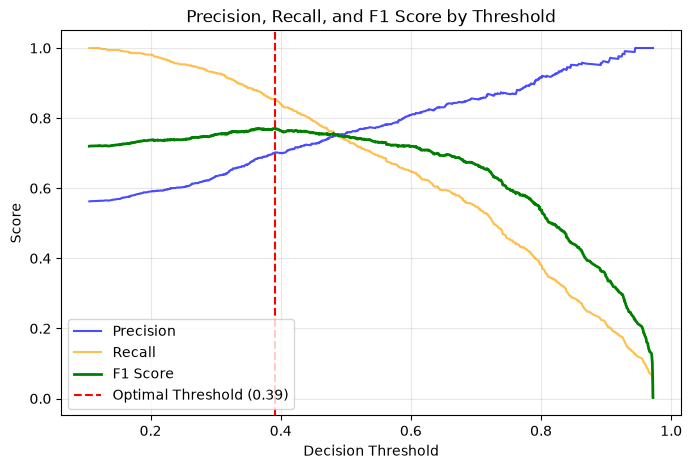

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label='Precision', color='blue', alpha=0.7)
plt.plot(thresholds, recalls[:-1], label='Recall', color='orange', alpha=0.7)
plt.plot(thresholds, f1_scores[:-1], label='F1 Score', color='green', linewidth=2)

# Mark the optimal threshold point
plt.axvline(x=best_threshold, color='red', linestyle='--', 
            label=f'Optimal Threshold ({best_threshold:.2f})')

plt.title('Precision, Recall, and F1 Score by Threshold')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.show()

/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_45239/1893364585.py:57: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(include=['object']).columns


HGB Best CV F1-Score: 0.7508
HGB Best Params: {'l2_regularization': np.float64(0.061820520641258085), 'learning_rate': np.float64(0.06556772775082419), 'max_iter': 346, 'max_leaf_nodes': 71, 'min_samples_leaf': 448}

Optimal Threshold for F1 Score: 0.3218
Maximum Validation F1 Score: 0.7578

ROC-AUC: 0.7859

--- CLASSIFICATION REPORT (Threshold = 0.3218) ---
              precision    recall  f1-score   support

           0       0.74      0.41      0.53       533
           1       0.66      0.89      0.76       685

    accuracy                           0.68      1218
   macro avg       0.70      0.65      0.64      1218
weighted avg       0.70      0.68      0.66      1218

--- FEATURE IMPORTANCE (Permutation, F1-Scoring) ---
                       Feature  Importance_Mean  Importance_Std
                          city         0.010892        0.005993
       purchase_count_181_365d         0.006315        0.007588
              transport_method         0.006184        0.003608
   

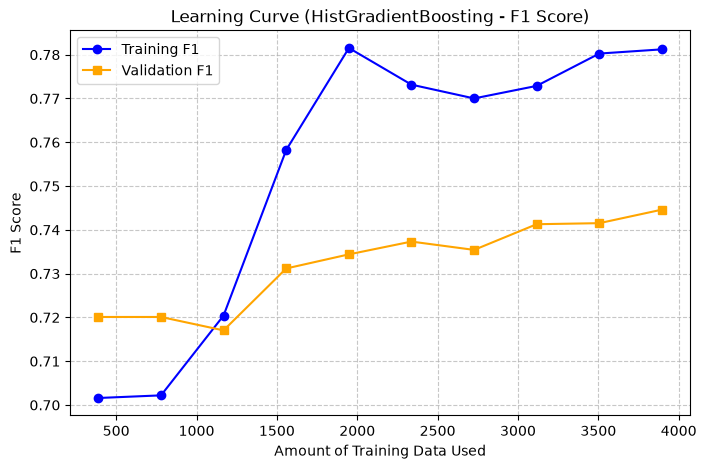

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint
from sklearn.model_selection import (train_test_split, learning_curve,
                                     RandomizedSearchCV, StratifiedKFold)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, precision_recall_curve, roc_auc_score

# ------------------------------------------------------------------
# 1. Preprocessing & Time Windows
# ------------------------------------------------------------------
train_clean = train.fillna(0)

# Convert cumulative overlapping features into non-overlapping windows
if 'spend_365d' in train_clean.columns:
    train_clean['spend_181_365d'] = train_clean['spend_365d'] - train_clean['spend_180d']
    train_clean['spend_91_180d'] = train_clean['spend_180d'] - train_clean['spend_90d']
    train_clean['spend_31_90d'] = train_clean['spend_90d'] - train_clean['spend_30d']
    train_clean = train_clean.drop(columns=['spend_365d', 'spend_180d', 'spend_90d'])

if 'purchase_count_365d' in train_clean.columns:
    train_clean['purchase_count_181_365d'] = train_clean['purchase_count_365d'] - train_clean['purchase_count_180d']
    train_clean['purchase_count_91_180d'] = train_clean['purchase_count_180d'] - train_clean['purchase_count_90d']
    train_clean['purchase_count_31_90d'] = train_clean['purchase_count_90d'] - train_clean['purchase_count_30d']
    train_clean = train_clean.drop(columns=['purchase_count_365d', 'purchase_count_180d', 'purchase_count_90d'])

    # 1. Average Order Value (Recent)
train_clean['aov_30d'] = train_clean['spend_30d'] / (train_clean['purchase_count_30d'] + 1e-5)

# 2. Average Order Value (Historical)
train_clean['aov_prior'] = train_clean['prior_total_spend'] / (train_clean['prior_purchase_count'] + 1e-5)

# 3. Spend Trend (Are they spending more now than they were last month?)
# > 1 means spending is accelerating, < 1 means they are cooling off
train_clean['spend_velocity'] = train_clean['spend_30d'] / (train_clean['spend_31_90d'] + 1e-5)

# ------------------------------------------------------------------
# 2. Drop Noise & Prepare Native Categoricals
# ------------------------------------------------------------------
# Drop columns that caused feature bloat with 0 or negative importance

# Drop original noise + new negative-importance features
noise_cols = [
    # # Original noise
    # 'address', 'postal_code', 'postal_area', 'city', 
    # 'municipality', 'island', 'company_name', 
    # 'warehouse', 'document_series', 'country_or_region', 
    'purchase_date','postal_code','address','company_name'
    # Invoice redundancy
]

train_clean = train_clean.drop(columns=[c for c in noise_cols if c in train_clean.columns], errors='ignore')

# Convert remaining strings to 'category' dtype (No pd.get_dummies!)
categorical_cols = train_clean.select_dtypes(include=['object']).columns
for col in categorical_cols:
    # Force everything to be a string first, which turns integer 0s into string '0's
    train_clean[col] = train_clean[col].astype(str).astype('category')

X = train_clean.drop('repeat_purchase_90d', axis=1)
y = train_clean['repeat_purchase_90d']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ------------------------------------------------------------------
# 3. Train HistGradientBoosting (Tuning for F1 Score)
# ------------------------------------------------------------------

hgb_search.fit(X_train, y_train)
best_model = hgb_search.best_estimator_

print(f"HGB Best CV F1-Score: {hgb_search.best_score_:.4f}")
print(f"HGB Best Params: {hgb_search.best_params_}\n")

# ------------------------------------------------------------------
# 4. Optimal Decision Threshold for F1
# ------------------------------------------------------------------
y_pred_prob = best_model.predict_proba(X_val)[:, 1]

# Calculate precision and recall across all possible thresholds
precisions, recalls, thresholds = precision_recall_curve(y_val, y_pred_prob)

# Calculate F1 score for each threshold, extract the highest
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_index = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print(f"Optimal Threshold for F1 Score: {best_threshold:.4f}")
print(f"Maximum Validation F1 Score: {best_f1:.4f}\n")
print(f"ROC-AUC: {roc_auc_score(y_val, y_pred_prob):.4f}\n")

y_pred_best_f1 = (y_pred_prob >= best_threshold).astype(int)

print(f"--- CLASSIFICATION REPORT (Threshold = {best_threshold:.4f}) ---")
print(classification_report(y_val, y_pred_best_f1))

# ------------------------------------------------------------------
# 5. Clean Feature Importance
# ------------------------------------------------------------------
perm = permutation_importance(best_model, X_val, y_val, scoring='f1',
                              n_repeats=10, random_state=42, n_jobs=-1)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance_Mean': perm.importances_mean,
    'Importance_Std': perm.importances_std,
}).sort_values('Importance_Mean', ascending=False)

print("--- FEATURE IMPORTANCE (Permutation, F1-Scoring) ---")
with pd.option_context('display.max_rows', None):
    print(importance_df.to_string(index=False))

# ------------------------------------------------------------------
# 6. Learning Curve (F1 metric)
# ------------------------------------------------------------------
sizes, tr_scores, va_scores = learning_curve(
    best_model, X_train, y_train, cv=5, scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)
plt.figure(figsize=(8, 5))
plt.plot(sizes, tr_scores.mean(axis=1), marker='o', color='blue', label='Training F1')
plt.plot(sizes, va_scores.mean(axis=1), marker='s', color='orange', label='Validation F1')
plt.title('Learning Curve (HistGradientBoosting - F1 Score)')
plt.xlabel('Amount of Training Data Used')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_45239/1963932006.py:51: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(include=['object']).columns


CatBoost Best CV F1-Score: 0.7505
CatBoost Best Params: {'depth': 4, 'iterations': 401, 'l2_leaf_reg': 45, 'learning_rate': np.float64(0.059963338824126605)}

Optimal Threshold for F1 Score: 0.3899
Maximum Validation F1 Score: 0.7657

ROC-AUC: 0.7917

--- CLASSIFICATION REPORT (Threshold = 0.3899) ---
              precision    recall  f1-score   support

           0       0.73      0.53      0.61       533
           1       0.70      0.85      0.77       685

    accuracy                           0.71      1218
   macro avg       0.71      0.69      0.69      1218
weighted avg       0.71      0.71      0.70      1218

--- FEATURE IMPORTANCE (Permutation, F1-Scoring) ---
                       Feature  Importance_Mean  Importance_Std
                   postal_area         0.001881        0.002339
               document_series         0.001583        0.001922
             Total Desc_ Linha         0.001367        0.002780
           customer_since_year         0.001309        0.0022

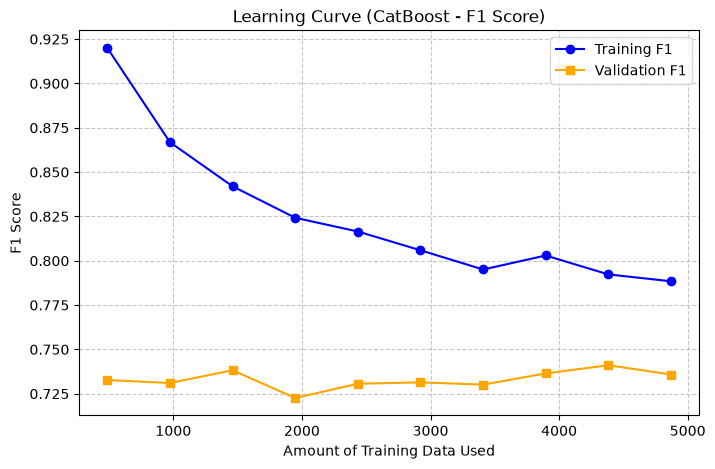

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint
from sklearn.model_selection import (train_test_split, learning_curve,
                                     RandomizedSearchCV, StratifiedKFold)
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, precision_recall_curve, roc_auc_score

# Import CatBoost
from catboost import CatBoostClassifier

# ------------------------------------------------------------------
# 1. Preprocessing & Time Windows
# ------------------------------------------------------------------
train_clean = train.fillna(0)

# Convert cumulative overlapping features into non-overlapping windows
if 'spend_365d' in train_clean.columns:
    train_clean['spend_181_365d'] = train_clean['spend_365d'] - train_clean['spend_180d']
    train_clean['spend_91_180d'] = train_clean['spend_180d'] - train_clean['spend_90d']
    train_clean['spend_31_90d'] = train_clean['spend_90d'] - train_clean['spend_30d']
    train_clean = train_clean.drop(columns=['spend_365d', 'spend_180d', 'spend_90d'])

if 'purchase_count_365d' in train_clean.columns:
    train_clean['purchase_count_181_365d'] = train_clean['purchase_count_365d'] - train_clean['purchase_count_180d']
    train_clean['purchase_count_91_180d'] = train_clean['purchase_count_180d'] - train_clean['purchase_count_90d']
    train_clean['purchase_count_31_90d'] = train_clean['purchase_count_90d'] - train_clean['purchase_count_30d']
    train_clean = train_clean.drop(columns=['purchase_count_365d', 'purchase_count_180d', 'purchase_count_90d'])

# 1. Average Order Value (Recent)
train_clean['aov_30d'] = train_clean['spend_30d'] / (train_clean['purchase_count_30d'] + 1e-5)

# 2. Average Order Value (Historical)
train_clean['aov_prior'] = train_clean['prior_total_spend'] / (train_clean['prior_purchase_count'] + 1e-5)

# 3. Spend Trend (Are they spending more now than they were last month?)
# > 1 means spending is accelerating, < 1 means they are cooling off
train_clean['spend_velocity'] = train_clean['spend_30d'] / (train_clean['spend_31_90d'] + 1e-5)

# ------------------------------------------------------------------
# 2. Drop Noise & Prepare Native Categoricals
# ------------------------------------------------------------------
noise_cols = [
    'purchase_date', 'postal_code', 'address', 'company_name'
]

train_clean = train_clean.drop(columns=[c for c in noise_cols if c in train_clean.columns], errors='ignore')

# Convert remaining strings to 'category' dtype
categorical_cols = train_clean.select_dtypes(include=['object']).columns
for col in categorical_cols:
    train_clean[col] = train_clean[col].astype(str).astype('category')

X = train_clean.drop('repeat_purchase_90d', axis=1)
y = train_clean['repeat_purchase_90d']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Extract a list of categorical column names for CatBoost
cat_features_list = X.select_dtypes(include=['category']).columns.tolist()

# ------------------------------------------------------------------
# 3. Train CatBoost (Tuning for F1 Score)
# ------------------------------------------------------------------
# Initialize CatBoost with cat_features so sklearn wrappers handle it natively
# ------------------------------------------------------------------
# 3. Train CatBoost (Tuning for F1 Score)
# ------------------------------------------------------------------
# Remove cat_features from the constructor
cb_base = CatBoostClassifier(
    eval_metric='F1',
    verbose=False, 
    random_state=42
)

cb_search = RandomizedSearchCV(
    cb_base,
    param_distributions={
        'learning_rate': loguniform(0.01, 0.2),
        'iterations': randint(200, 800),
        'depth': randint(3, 5),
        'l2_leaf_reg': randint(10, 50),
    },
    n_iter=20, 
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    refit=True
)

# Pass cat_features directly into the fit method here
cb_search.fit(X_train, y_train, cat_features=cat_features_list)

best_model = cb_search.best_estimator_

print(f"CatBoost Best CV F1-Score: {cb_search.best_score_:.4f}")
print(f"CatBoost Best Params: {cb_search.best_params_}\n")

# ------------------------------------------------------------------
# 4. Optimal Decision Threshold for F1
# ------------------------------------------------------------------
y_pred_prob = best_model.predict_proba(X_val)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_val, y_pred_prob)

f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_index = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print(f"Optimal Threshold for F1 Score: {best_threshold:.4f}")
print(f"Maximum Validation F1 Score: {best_f1:.4f}\n")
print(f"ROC-AUC: {roc_auc_score(y_val, y_pred_prob):.4f}\n")

y_pred_best_f1 = (y_pred_prob >= best_threshold).astype(int)

print(f"--- CLASSIFICATION REPORT (Threshold = {best_threshold:.4f}) ---")
print(classification_report(y_val, y_pred_best_f1))

# ------------------------------------------------------------------
# 5. Clean Feature Importance
# ------------------------------------------------------------------
perm = permutation_importance(best_model, X_val, y_val, scoring='f1',
                              n_repeats=10, random_state=42, n_jobs=-1)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance_Mean': perm.importances_mean,
    'Importance_Std': perm.importances_std,
}).sort_values('Importance_Mean', ascending=False)

print("--- FEATURE IMPORTANCE (Permutation, F1-Scoring) ---")
with pd.option_context('display.max_rows', None):
    print(importance_df.to_string(index=False))

# ------------------------------------------------------------------
# 6. Learning Curve (F1 metric) - Custom for CatBoost
# ------------------------------------------------------------------
print("Generating Learning Curve...")
train_sizes_fractions = np.linspace(0.1, 1.0, 10)
train_sizes_counts = []
tr_scores = []
va_scores = []

for size in train_sizes_fractions:
    # 1. Take a percentage of the training data
    if size == 1.0:
        X_subset, y_subset = X_train, y_train
    else:
        X_subset, _, y_subset, _ = train_test_split(
            X_train, y_train, train_size=size, stratify=y_train, random_state=42
        )
    
    train_sizes_counts.append(len(X_subset))
    
    # 2. Initialize a fresh model with your best parameters
    cb_curve_model = CatBoostClassifier(
        **cb_search.best_params_, 
        eval_metric='F1', 
        verbose=False, 
        random_state=42
    )
    
    # 3. Fit safely with cat_features
    cb_curve_model.fit(X_subset, y_subset, cat_features=cat_features_list)
    
    # 4. Score Training and Validation
    y_train_pred = cb_curve_model.predict(X_subset)
    y_val_pred = cb_curve_model.predict(X_val)
    
    # Convert CatBoost string outputs ('0', '1') back to integers if necessary
    tr_scores.append(f1_score(y_subset, y_train_pred.astype(int)))
    va_scores.append(f1_score(y_val, y_val_pred.astype(int)))

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(train_sizes_counts, tr_scores, marker='o', color='blue', label='Training F1')
plt.plot(train_sizes_counts, va_scores, marker='s', color='orange', label='Validation F1')
plt.title('Learning Curve (CatBoost - F1 Score)')
plt.xlabel('Amount of Training Data Used')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_45239/959838977.py:59: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(include=['object']).columns


XGBoost Best CV F1-Score: 0.7565
XGBoost Best Params: {'colsample_bytree': np.float64(0.9464704583099741), 'learning_rate': np.float64(0.05092911283433821), 'max_depth': 6, 'min_child_weight': 3, 'n_estimators': 508, 'reg_alpha': np.float64(8.123245085588687), 'reg_lambda': np.float64(25.95942550311264), 'subsample': np.float64(0.6849356442713105)}

Optimal Threshold for F1 Score: 0.4173
Maximum Validation F1 Score: 0.7772

ROC-AUC: 0.8120

--- CLASSIFICATION REPORT (Threshold = 0.4173) ---
              precision    recall  f1-score   support

           0       0.73      0.61      0.67       533
           1       0.73      0.83      0.78       685

    accuracy                           0.73      1218
   macro avg       0.73      0.72      0.72      1218
weighted avg       0.73      0.73      0.73      1218

--- FEATURE IMPORTANCE (Permutation, F1-Scoring) ---
                       Feature  Importance_Mean  Importance_Std
                purchase_month         0.015150        0.003

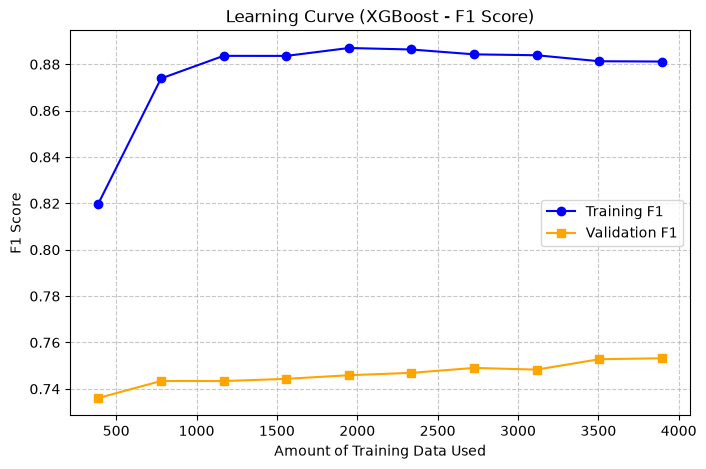

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import (train_test_split, learning_curve,
                                     RandomizedSearchCV, StratifiedKFold)
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, precision_recall_curve, roc_auc_score

# Import XGBoost
from xgboost import XGBClassifier

# ------------------------------------------------------------------
# 1. Preprocessing, Time Windows, & Date Extraction
# ------------------------------------------------------------------
train_clean = train.copy()

# Fix dates BEFORE filling all NaNs with 0
if 'purchase_date' in train_clean.columns:
    train_clean['purchase_date'] = pd.to_datetime(train_clean['purchase_date'], errors='coerce')
    train_clean['purchase_year'] = train_clean['purchase_date'].dt.year
    train_clean['purchase_month'] = train_clean['purchase_date'].dt.month
    train_clean['purchase_day'] = train_clean['purchase_date'].dt.day
    train_clean['purchase_dayofweek'] = train_clean['purchase_date'].dt.dayofweek
    
    reference_date = train_clean['purchase_date'].min()
    train_clean['days_since_first_purchase'] = (train_clean['purchase_date'] - reference_date).dt.days
    train_clean = train_clean.drop(columns=['purchase_date'])

train_clean = train_clean.fillna(0)

# Convert cumulative overlapping features into non-overlapping windows
if 'spend_365d' in train_clean.columns:
    train_clean['spend_181_365d'] = train_clean['spend_365d'] - train_clean['spend_180d']
    train_clean['spend_91_180d'] = train_clean['spend_180d'] - train_clean['spend_90d']
    train_clean['spend_31_90d'] = train_clean['spend_90d'] - train_clean['spend_30d']
    train_clean = train_clean.drop(columns=['spend_365d', 'spend_180d', 'spend_90d'])

if 'purchase_count_365d' in train_clean.columns:
    train_clean['purchase_count_181_365d'] = train_clean['purchase_count_365d'] - train_clean['purchase_count_180d']
    train_clean['purchase_count_91_180d'] = train_clean['purchase_count_180d'] - train_clean['purchase_count_90d']
    train_clean['purchase_count_31_90d'] = train_clean['purchase_count_90d'] - train_clean['purchase_count_30d']
    train_clean = train_clean.drop(columns=['purchase_count_365d', 'purchase_count_180d', 'purchase_count_90d'])

# Engineering Momentum & Velocity Features
train_clean['aov_30d'] = train_clean['spend_30d'] / (train_clean['purchase_count_30d'] + 1e-5)
train_clean['aov_prior'] = train_clean['prior_total_spend'] / (train_clean['prior_purchase_count'] + 1e-5)
train_clean['spend_velocity'] = train_clean['spend_30d'] / (train_clean['spend_31_90d'] + 1e-5)

# ------------------------------------------------------------------
# 2. Drop Noise & Prepare Native Categoricals
# ------------------------------------------------------------------
noise_cols = [
    'postal_code', 'address', 'company_name'
]
train_clean = train_clean.drop(columns=[c for c in noise_cols if c in train_clean.columns], errors='ignore')

# XGBoost requires string columns to be strictly 'category' dtype
categorical_cols = train_clean.select_dtypes(include=['object']).columns
for col in categorical_cols:
    train_clean[col] = train_clean[col].astype(str).astype('category')

X = train_clean.drop('repeat_purchase_90d', axis=1)
y = train_clean['repeat_purchase_90d']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ------------------------------------------------------------------
# 3. Train XGBoost (Tuning for F1 Score)
# ------------------------------------------------------------------
xgb_base = XGBClassifier(
    enable_categorical=True,  # Allows XGBoost to process 'category' types directly
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_search = RandomizedSearchCV(
    xgb_base,
    param_distributions={
        'learning_rate': loguniform(0.01, 0.15),
        'n_estimators': randint(200, 800),
        'max_depth': randint(3, 7),               # Kept low to combat overfitting
        'min_child_weight': randint(1, 10),       # Minimum sum of instance weight in a child
        'subsample': uniform(0.6, 0.4),           # Randomly sample 60-100% of rows per tree
        'colsample_bytree': uniform(0.6, 0.4),    # Randomly sample 60-100% of columns per tree
        'reg_alpha': loguniform(1e-2, 10),        # L1 Regularization to zero out noise
        'reg_lambda': loguniform(1, 50),          # High L2 Regularization to combat overfitting
    },
    n_iter=30, 
    cv=cv, 
    scoring='f1', 
    n_jobs=-1, 
    random_state=42, 
    refit=True
)

xgb_search.fit(X_train, y_train)
best_model = xgb_search.best_estimator_

print(f"XGBoost Best CV F1-Score: {xgb_search.best_score_:.4f}")
print(f"XGBoost Best Params: {xgb_search.best_params_}\n")

# ------------------------------------------------------------------
# 4. Optimal Decision Threshold for F1
# ------------------------------------------------------------------
y_pred_prob = best_model.predict_proba(X_val)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_val, y_pred_prob)

f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_index = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print(f"Optimal Threshold for F1 Score: {best_threshold:.4f}")
print(f"Maximum Validation F1 Score: {best_f1:.4f}\n")
print(f"ROC-AUC: {roc_auc_score(y_val, y_pred_prob):.4f}\n")

y_pred_best_f1 = (y_pred_prob >= best_threshold).astype(int)

print(f"--- CLASSIFICATION REPORT (Threshold = {best_threshold:.4f}) ---")
print(classification_report(y_val, y_pred_best_f1))

# ------------------------------------------------------------------
# 5. Clean Feature Importance
# ------------------------------------------------------------------
perm = permutation_importance(best_model, X_val, y_val, scoring='f1',
                              n_repeats=10, random_state=42, n_jobs=-1)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance_Mean': perm.importances_mean,
    'Importance_Std': perm.importances_std,
}).sort_values('Importance_Mean', ascending=False)

print("--- FEATURE IMPORTANCE (Permutation, F1-Scoring) ---")
with pd.option_context('display.max_rows', None):
    print(importance_df.to_string(index=False))

# ------------------------------------------------------------------
# 6. Learning Curve (F1 metric)
# ------------------------------------------------------------------
# XGBoost works seamlessly with sklearn's learning_curve via enable_categorical=True
sizes, tr_scores, va_scores = learning_curve(
    best_model, X_train, y_train, cv=5, scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)
plt.figure(figsize=(8, 5))
plt.plot(sizes, tr_scores.mean(axis=1), marker='o', color='blue', label='Training F1')
plt.plot(sizes, va_scores.mean(axis=1), marker='s', color='orange', label='Validation F1')
plt.title('Learning Curve (XGBoost - F1 Score)')
plt.xlabel('Amount of Training Data Used')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin
from catboost import CatBoostClassifier

class CatBoostWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, **params):
        self.params = params
        self.model = CatBoostClassifier(**params, verbose=False)
        
    def fit(self, X, y, **fit_params):
        # Save unique classes required by scikit-learn's StackingClassifier
        self.classes_ = np.unique(y)
        
        # Automatically find categorical columns and their indices inside X
        cat_cols = X.select_dtypes(include=['category', 'object']).columns.tolist()
        cat_indices = [X.columns.get_loc(col) for col in cat_cols]
        
        # Fit CatBoost with the automatically detected indices
        self.model.fit(X, y, cat_features=cat_indices, **fit_params)
        return self
        
    def predict(self, X):
        return self.model.predict(X)
        
    def predict_proba(self, X):
        return self.model.predict_proba(X)
        
    def get_params(self, deep=True):
        return self.params
        
    def set_params(self, **params):
        self.params.update(params)
        self.model.set_params(**params)
        return self

In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

wrapped_cat = CatBoostWrapper(**cb_search.best_params_)

stacking_model = StackingClassifier(
    estimators=[
        ('cat', wrapped_cat),
        ('xgb', xgb_search.best_estimator_),
        ('hgb', hgb_search.best_estimator_)
    ],
    final_estimator=LogisticRegression(C=0.2,penalty='l2',random_state=42),
    cv=5,
    n_jobs=-1
)
stacking_model.fit(X_train, y_train)
y_pred_prob = stacking_model.predict_proba(X_val)[:, 1]
print(f"Stacking ROC-AUC: {roc_auc_score(y_val, y_pred_prob):.4f}")

Stacking ROC-AUC: 0.8094


/Users/macbookpro/NovaWorkspace/MachineLearning/FinalProject/Project/ML_Group_22/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, classification_report, 
                             precision_recall_curve, roc_auc_score)
import numpy as np

# 1. Get raw probabilities for the validation set from the Stacking model
y_pred_prob = stacking_model.predict_proba(X_val)[:, 1]

# 2. Find the mathematical peak for the F1 score across all thresholds
precisions, recalls, thresholds = precision_recall_curve(y_val, y_pred_prob)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_index = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_index]

# 3. Apply the optimal threshold to get hard predictions (0 or 1)
y_pred_optimal = (y_pred_prob >= best_threshold).astype(int)

# 4. Calculate comprehensive metrics
acc = accuracy_score(y_val, y_pred_optimal)
prec = precision_score(y_val, y_pred_optimal, average='binary')
rec = recall_score(y_val, y_pred_optimal, average='binary')
f1 = f1_score(y_val, y_pred_optimal, average='binary')
roc_auc = roc_auc_score(y_val, y_pred_prob)

# 5. Print clean summary
print("================ STACKING MODEL PERFORMANCE ================")
print(f"Optimal Decision Threshold : {best_threshold:.4f}")
print(f"Validation ROC-AUC         : {roc_auc:.4f}")
print(f"Accuracy                   : {acc:.4f}")
print(f"Precision (Class 1)        : {prec:.4f}")
print(f"Recall (Class 1)           : {rec:.4f}")
print(f"F1 Score (Class 1)         : {f1:.4f}\n")

print("------------------ CLASSIFICATION REPORT ------------------")
print(classification_report(y_val, y_pred_optimal))

================ STACKING MODEL PERFORMANCE ================
Optimal Decision Threshold : 0.4598
Validation ROC-AUC         : 0.8094
Accuracy                   : 0.7389
Precision (Class 1)        : 0.7524
Recall (Class 1)           : 0.7985
F1 Score (Class 1)         : 0.7748

------------------ CLASSIFICATION REPORT ------------------
              precision    recall  f1-score   support

           0       0.72      0.66      0.69       533
           1       0.75      0.80      0.77       685

    accuracy                           0.74      1218
   macro avg       0.74      0.73      0.73      1218
weighted avg       0.74      0.74      0.74      1218



/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_45239/1415230793.py:65: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_clean.select_dtypes(include=['object']).columns


XGBoost Best CV F1-Score: 0.7563
XGBoost Best Params: {'colsample_bytree': np.float64(0.6557975442608167), 'learning_rate': np.float64(0.022059149678071027), 'max_depth': 6, 'min_child_weight': 3, 'n_estimators': 766, 'reg_alpha': np.float64(8.906204386161678), 'reg_lambda': np.float64(6.208921295733548), 'subsample': np.float64(0.9439761626945282)}

Optimal Threshold for F1 Score: 0.3919
Maximum Validation F1 Score: 0.7748

ROC-AUC: 0.8122

--- CLASSIFICATION REPORT (Threshold = 0.3919) ---
              precision    recall  f1-score   support

           0       0.74      0.57      0.64       533
           1       0.72      0.84      0.77       685

    accuracy                           0.72      1218
   macro avg       0.73      0.71      0.71      1218
weighted avg       0.73      0.72      0.72      1218

--- FEATURE IMPORTANCE (Permutation, F1-Scoring) ---
                       Feature  Importance_Mean  Importance_Std
                purchase_month         0.020034        0.00

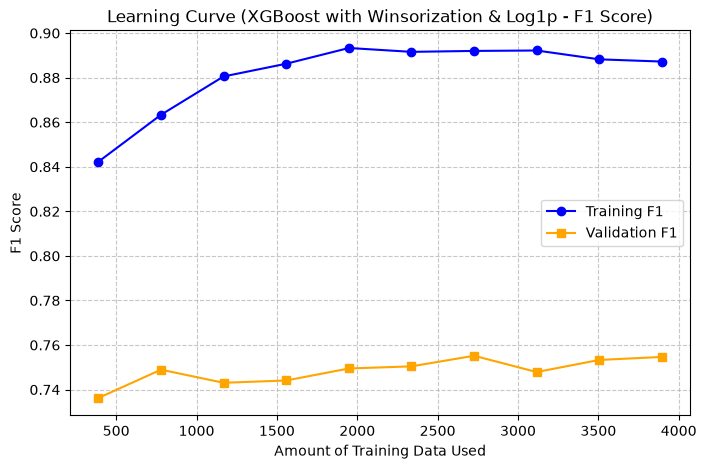

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import (train_test_split, learning_curve,
                                     RandomizedSearchCV, StratifiedKFold)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             precision_recall_curve)
from xgboost import XGBClassifier

# ------------------------------------------------------------------
# 1. Preprocessing, Time Windows, & Date Extraction
# ------------------------------------------------------------------
train_clean = train.copy()

# Fix dates before filling NaNs
if 'purchase_date' in train_clean.columns:
    train_clean['purchase_date'] = pd.to_datetime(train_clean['purchase_date'], errors='coerce')
    train_clean['purchase_year'] = train_clean['purchase_date'].dt.year
    train_clean['purchase_month'] = train_clean['purchase_date'].dt.month
    train_clean['purchase_day'] = train_clean['purchase_date'].dt.day
    train_clean['purchase_dayofweek'] = train_clean['purchase_date'].dt.dayofweek
    
    reference_date = train_clean['purchase_date'].min()
    train_clean['days_since_first_purchase'] = (train_clean['purchase_date'] - reference_date).dt.days
    train_clean = train_clean.drop(columns=['purchase_date'])


# Convert cumulative overlapping features into non-overlapping windows
if 'spend_365d' in train_clean.columns:
    train_clean['spend_181_365d'] = train_clean['spend_365d'] - train_clean['spend_180d']
    train_clean['spend_91_180d'] = train_clean['spend_180d'] - train_clean['spend_90d']
    train_clean['spend_31_90d'] = train_clean['spend_90d'] - train_clean['spend_30d']
    train_clean = train_clean.drop(columns=['spend_365d', 'spend_180d', 'spend_90d'])

if 'purchase_count_365d' in train_clean.columns:
    train_clean['purchase_count_181_365d'] = train_clean['purchase_count_365d'] - train_clean['purchase_count_180d']
    train_clean['purchase_count_91_180d'] = train_clean['purchase_count_180d'] - train_clean['purchase_count_90d']
    train_clean['purchase_count_31_90d'] = train_clean['purchase_count_90d'] - train_clean['purchase_count_30d']
    train_clean = train_clean.drop(columns=['purchase_count_365d', 'purchase_count_180d', 'purchase_count_90d'])

# Engineering Momentum & Velocity Features
train_clean['aov_30d'] = train_clean['spend_30d'] / (train_clean['purchase_count_30d'] + 1e-5)
train_clean['aov_prior'] = train_clean['prior_total_spend'] / (train_clean['prior_purchase_count'] + 1e-5)
train_clean['spend_velocity'] = train_clean['spend_30d'] / (train_clean['spend_31_90d'] + 1e-5)

# ------------------------------------------------------------------
# 2. Winsorization & Log1p Transformation on Skewed Numerical Columns
# ------------------------------------------------------------------
# Identify numerical columns (excluding target and dates/binary flags)
exclude_cols = ['repeat_purchase_90d', 'purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek']
num_cols = train_clean.select_dtypes(include=[np.number]).columns
num_cols = [c for c in num_cols if c not in exclude_cols]


# ------------------------------------------------------------------
# 3. Drop Noise & Prepare Native Categoricals
# ------------------------------------------------------------------
noise_cols = ['postal_code', 'address', 'company_name']
train_clean = train_clean.drop(columns=[c for c in noise_cols if c in train_clean.columns], errors='ignore')

# XGBoost requires string columns to be strictly 'category' dtype
categorical_cols = train_clean.select_dtypes(include=['object']).columns
for col in categorical_cols:
    train_clean[col] = train_clean[col].astype(str).astype('category')

X = train_clean.drop('repeat_purchase_90d', axis=1)
y = train_clean['repeat_purchase_90d']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ------------------------------------------------------------------
# 4. Train XGBoost (Optimizing for F1 Score)
# ------------------------------------------------------------------
xgb_base = XGBClassifier(
    enable_categorical=True,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_search = RandomizedSearchCV(
    xgb_base,
    param_distributions={
        'learning_rate': loguniform(0.01, 0.15),
        'n_estimators': randint(200, 800),
        'max_depth': randint(3, 7),
        'min_child_weight': randint(1, 10),
        'subsample': uniform(0.6, 0.4),
        'colsample_bytree': uniform(0.6, 0.4),
        'reg_alpha': loguniform(1e-2, 10),
        'reg_lambda': loguniform(1, 50),
    },
    n_iter=30, 
    cv=cv, 
    scoring='f1', 
    n_jobs=-1, 
    random_state=42, 
    refit=True
)

xgb_search.fit(X_train, y_train)
best_model = xgb_search.best_estimator_

print(f"XGBoost Best CV F1-Score: {xgb_search.best_score_:.4f}")
print(f"XGBoost Best Params: {xgb_search.best_params_}\n")

# ------------------------------------------------------------------
# 5. Optimal Decision Threshold for F1
# ------------------------------------------------------------------
y_pred_prob = best_model.predict_proba(X_val)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_val, y_pred_prob)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_index = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print(f"Optimal Threshold for F1 Score: {best_threshold:.4f}")
print(f"Maximum Validation F1 Score: {best_f1:.4f}\n")
print(f"ROC-AUC: {roc_auc_score(y_val, y_pred_prob):.4f}\n")

y_pred_best_f1 = (y_pred_prob >= best_threshold).astype(int)

print(f"--- CLASSIFICATION REPORT (Threshold = {best_threshold:.4f}) ---")
print(classification_report(y_val, y_pred_best_f1))

# ------------------------------------------------------------------
# 6. Permutation Feature Importance
# ------------------------------------------------------------------
perm = permutation_importance(best_model, X_val, y_val, scoring='f1',
                              n_repeats=10, random_state=42, n_jobs=-1)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance_Mean': perm.importances_mean,
    'Importance_Std': perm.importances_std,
}).sort_values('Importance_Mean', ascending=False)

print("--- FEATURE IMPORTANCE (Permutation, F1-Scoring) ---")
with pd.option_context('display.max_rows', None):
    print(importance_df.to_string(index=False))

# ------------------------------------------------------------------
# 7. Learning Curve (F1 metric)
# ------------------------------------------------------------------
sizes, tr_scores, va_scores = learning_curve(
    best_model, X_train, y_train, cv=5, scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)
plt.figure(figsize=(8, 5))
plt.plot(sizes, tr_scores.mean(axis=1), marker='o', color='blue', label='Training F1')
plt.plot(sizes, va_scores.mean(axis=1), marker='s', color='orange', label='Validation F1')
plt.title('Learning Curve (XGBoost with Winsorization & Log1p - F1 Score)')
plt.xlabel('Amount of Training Data Used')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## IV.2 Resampling Method
Stratified 10-fold CV; nested CV if tuning hyperparameters.

====missing work here=====

## IV.3 Classification Metrics
Precision, Recall, F1, Balanced Accuracy, ROC-AUC, PR-AUC.

====missing work here=====

## IV.4 Threshold Tuning
Precision-Recall curves to choose the probability cutoff.

====missing work here=====

## IV.5 Statistical Significance
Paired / resampled t-test on CV folds, or McNemar's test on a single hold-out.

====missing work here=====

---
# V. Final Output & Deliverables
## V.1 Kaggle Submission
Predictions for the 986 observations in `test.csv`, without altering the ID column, formatted identically to `sample_submission.csv`.

====missing work here=====

## V.2 Deliverable 2: 2-page PDF
Pipeline schematic plus justification of feature selection, evaluation metrics, and preprocessing.

====missing work here=====

In [ ]:
"""Repeat-purchase (90d) pipeline: one file, ~100 lines.

What it does
  1. Builds features on train+test together (same code, no rows dropped).
  2. Validates with StratifiedGroupKFold on customer_id (honest estimate).
  3. Averages XGBoost + HistGradientBoosting over a few seeds.
  4. Picks the F1-optimal threshold on out-of-fold predictions.
  5. Writes submission.csv.
"""
import os
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from xgboost import XGBClassifier

DATA_DIR = os.environ.get("DATA_DIR", "../data")
TARGET = "repeat_purchase_90d"
SEEDS = [0, 1, 2]
# Uses the date of the customer's NEXT row in train+test. Strong, but it peeks at
# "the future" -> only switch on if your assignment rules allow it.
USE_NEXT_ROW = False

# ---------------------------------------------------------------- load
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
clients = pd.read_csv(f"{DATA_DIR}/clientes.csv")

n_train = len(train)
df = pd.concat([train, test], ignore_index=True).merge(
    clients, on="customer_id", how="left", validate="many_to_one")


# ---------------------------------------------------------------- features
def build_features(d):
    d = d.copy()
    num = d.select_dtypes("number").columns.drop([TARGET, "ID", "customer_id"], errors="ignore")
    d["n_missing"] = d[num].isna().sum(axis=1)          # "no history" rows miss many columns together

    # dates
    d["purchase_date"] = pd.to_datetime(d["purchase_date"], errors="coerce")
    d["month"] = d["purchase_date"].dt.month
    d["dow"] = d["purchase_date"].dt.dayofweek
    d["day_idx"] = (d["purchase_date"] - d["purchase_date"].min()).dt.days
    d["days_to_end"] = d["day_idx"].max() - d["day_idx"]  # label is cut off near the end of the data

    # cumulative windows -> non-overlapping windows
    for p in ["spend", "purchase_count"]:
        d[f"{p}_31_90d"] = d[f"{p}_90d"] - d[f"{p}_30d"]
        d[f"{p}_91_180d"] = d[f"{p}_180d"] - d[f"{p}_90d"]
        d[f"{p}_181_365d"] = d[f"{p}_365d"] - d[f"{p}_180d"]
        d = d.drop(columns=[f"{p}_90d", f"{p}_180d", f"{p}_365d"])

    # ratios (NaN when the denominator is 0; trees handle NaN natively)
    d["aov_30d"] = d["spend_30d"] / d["purchase_count_30d"].replace(0, np.nan)
    d["aov_prior"] = d["prior_total_spend"] / d["prior_purchase_count"].replace(0, np.nan)
    d["spend_velocity"] = d["spend_30d"] / d["spend_31_90d"].replace(0, np.nan)
    d["gap_ratio"] = d["days_since_previous_purchase"] / d["prior_mean_gap_days"].replace(0, np.nan)

    # customer features from train+test rows (no labels used)
    ordered = d.sort_values("purchase_date").groupby("customer_id")["purchase_date"]
    d["cust_rows"] = d.groupby("customer_id")["purchase_date"].transform("size")
    d["days_since_prev_row"] = ordered.diff().dt.days
    if USE_NEXT_ROW:
        d["days_to_next_row"] = -ordered.diff(-1).dt.days

    # categoricals: rare levels merged, NaN kept as its own level
    drop = ["ID", "customer_id", "random_noise", "customer_type", "street", "address",
            "postal_code", "company_name", "commercial_zone", "warehouse", "purchase_date", TARGET]
    d = d.drop(columns=drop, errors="ignore")
    for c in d.select_dtypes(include=["object", "string"]).columns:
        s = d[c].astype(object)
        rare = s.value_counts()[lambda v: v < 30].index
        d[c] = s.where(~s.isin(rare), "rare").fillna("missing").astype("category")
    return d


X_all = build_features(df)
X, X_test = X_all.iloc[:n_train], X_all.iloc[n_train:]
y = train[TARGET].reset_index(drop=True)
groups = train["customer_id"].values


def models(seed):
    return [
        XGBClassifier(n_estimators=766, learning_rate=0.022, max_depth=6, min_child_weight=3,
                      subsample=0.94, colsample_bytree=0.66, reg_alpha=8.9, reg_lambda=6.2,
                      enable_categorical=True, tree_method="hist", random_state=seed, n_jobs=-1),
        HistGradientBoostingClassifier(learning_rate=0.03, max_iter=400, max_leaf_nodes=15,
                                       min_samples_leaf=40, l2_regularization=5,
                                       categorical_features="from_dtype", random_state=seed),
    ]


def fit_predict(X_tr, y_tr, X_te):
    preds = [m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1] for s in SEEDS for m in models(s)]
    return np.mean(preds, axis=0)


# ---------------------------------------------------------------- honest CV
oof = np.zeros(len(X))
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
for tr, va in cv.split(X, y, groups):
    oof[va] = fit_predict(X.iloc[tr], y.iloc[tr], X.iloc[va])

prec, rec, thr = precision_recall_curve(y, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
best = np.argmax(f1[:-1])
threshold = thr[best]

base = 2 * y.mean() / (1 + y.mean())
print(f"predict-all-1 baseline F1 : {base:.4f}")
print(f"OOF ROC-AUC               : {roc_auc_score(y, oof):.4f}")
print(f"OOF F1 @ 0.50             : {f1_score(y, oof >= 0.5):.4f}")
print(f"OOF F1 @ {threshold:.3f} (best)    : {f1[best]:.4f}")

# ---------------------------------------------------------------- submission
test_prob = fit_predict(X, y, X_test)
pred = (test_prob >= threshold).astype(int)

sample_path = f"{DATA_DIR}/sample_submission.csv"
if os.path.exists(sample_path):
    sub = pd.read_csv(sample_path)
    sub[sub.columns[0]] = test["ID"].values
    sub[sub.columns[1]] = pred
else:
    sub = pd.DataFrame({"ID": test["ID"].values, TARGET: pred})
sub.to_csv("submission.csv", index=False)
print(f"saved submission.csv ({len(sub)} rows, {pred.mean():.1%} predicted positive)")

predict-all-1 baseline F1 : 0.7173
OOF ROC-AUC               : 0.8234
OOF F1 @ 0.50             : 0.7741
OOF F1 @ 0.410 (best)    : 0.7805
saved submission.csv (986 rows, 69.2% predicted positive)


In [ ]:
"""Repeat-purchase (90d) pipeline: one file, ~100 lines.

What it does
  1. Builds features on train+test together (same code, no rows dropped).
  2. Validates with StratifiedGroupKFold on customer_id (honest estimate).
  3. Tests each extra-feature block (quick XGBoost CV) and keeps the ones that help.
  4. Averages XGBoost + HistGradientBoosting over a few seeds.
  5. Picks the F1-optimal threshold on out-of-fold predictions.
  6. Writes submission.csv.
"""
import os
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from xgboost import XGBClassifier

DATA_DIR = os.environ.get("DATA_DIR", "../data")
TARGET = "repeat_purchase_90d"
SEEDS = [0, 1, 2]
# Uses the date of the customer's NEXT row in train+test. Strong, but it peeks at
# "the future" -> only switch on if your assignment rules allow it.
USE_NEXT_ROW = False
ALL_BLOCKS = ["gap", "rate", "invoice", "vs_customer", "customer_rows", "time"]
MIN_GAIN = 0.002   # a block is kept if it raises OOF ROC-AUC by at least this much

# ---------------------------------------------------------------- load
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
clients = pd.read_csv(f"{DATA_DIR}/clientes.csv")

n_train = len(train)
df = pd.concat([train, test], ignore_index=True).merge(
    clients, on="customer_id", how="left", validate="many_to_one")


# ---------------------------------------------------------------- features
def build_features(d, blocks=()):
    d = d.copy()
    num = d.select_dtypes("number").columns.drop([TARGET, "ID", "customer_id"], errors="ignore")
    d["n_missing"] = d[num].isna().sum(axis=1)          # "no history" rows miss many columns together

    # dates
    d["purchase_date"] = pd.to_datetime(d["purchase_date"], errors="coerce")
    d["month"] = d["purchase_date"].dt.month
    d["dow"] = d["purchase_date"].dt.dayofweek
    d["day_idx"] = (d["purchase_date"] - d["purchase_date"].min()).dt.days
    d["days_to_end"] = d["day_idx"].max() - d["day_idx"]  # label is cut off near the end of the data

    # ---- extra feature blocks (computed on the raw cumulative windows) ----
    nz = lambda c: d[c].replace(0, np.nan)                      # avoid divide-by-zero
    if "gap" in blocks:            # will the next purchase land inside 90 days?
        mean_gap, std_gap = d["prior_mean_gap_days"], nz("prior_std_gap_days")
        d["gap_z"] = (d["days_since_previous_purchase"] - mean_gap) / std_gap
        d["p_gap_under_90"] = norm.cdf((90 - mean_gap) / std_gap)
        d["mean_gap_minus_90"] = mean_gap - 90
        d["expected_next_month"] = (d["purchase_date"] + pd.to_timedelta(mean_gap, unit="D")).dt.month
    if "rate" in blocks:           # purchase frequency and its recent trend
        d["buy_rate"] = d["prior_purchase_count"] / nz("customer_tenure_days")
        d["expected_90d"] = d["buy_rate"] * 90
        d["count_share_30d"] = d["purchase_count_30d"] / nz("purchase_count_365d")
        d["count_trend"] = d["purchase_count_90d"] / (nz("purchase_count_365d") / 4)
        d["spend_share_30d"] = d["spend_30d"] / nz("spend_365d")
    if "invoice" in blocks:        # shape of the current invoice
        d["discount_rate"] = (d["Total Desc_ Linha"] + d["Total Desc_ Global"]) / nz("Total Bruto")
        d["margin"] = (d["Total Liquido"] - d["Custo"]) / nz("Total Liquido")
        d["tax_rate"] = d["Total Imp_"] / nz("Total Liquido")
        d["ship_share"] = d["Total Portes"] / nz("Total a Pagar")
        d["value_per_line"] = d["Total Liquido"] / nz("N_ Detalhes")
    if "vs_customer" in blocks:    # current invoice vs this customer's history
        d["pay_vs_prior_mean"] = d["Total a Pagar"] / nz("prior_mean_purchase_value")
        d["pay_z"] = (d["Total a Pagar"] - d["prior_mean_purchase_value"]) / nz("prior_std_purchase_value")
        d["pay_vs_prior_max"] = d["Total a Pagar"] / nz("prior_max_purchase_value")
    if "customer_rows" in blocks:  # aggregates over the customer's train+test rows (no labels)
        g = d.groupby("customer_id")
        d["cust_pay_median"] = g["Total a Pagar"].transform("median")   # median: robust to corrupt rows
        d["pay_vs_cust_median"] = d["Total a Pagar"] / d["cust_pay_median"].replace(0, np.nan)
        d["cust_n_salesperson"] = g["salesperson"].transform("nunique")
        d["cust_span_days"] = g["day_idx"].transform("max") - g["day_idx"].transform("min")
        d["days_since_cust_first_row"] = d["day_idx"] - g["day_idx"].transform("min")
        d["cust_row_rank"] = g["day_idx"].rank(method="first")
    if "time" in blocks:
        d["month_sin"] = np.sin(2 * np.pi * d["month"] / 12)
        d["month_cos"] = np.cos(2 * np.pi * d["month"] / 12)
        d["week"] = d["purchase_date"].dt.isocalendar().week.astype(float)
        d["is_month_end"] = d["purchase_date"].dt.is_month_end.astype(int)

    # cumulative windows -> non-overlapping windows
    for p in ["spend", "purchase_count"]:
        d[f"{p}_31_90d"] = d[f"{p}_90d"] - d[f"{p}_30d"]
        d[f"{p}_91_180d"] = d[f"{p}_180d"] - d[f"{p}_90d"]
        d[f"{p}_181_365d"] = d[f"{p}_365d"] - d[f"{p}_180d"]
        d = d.drop(columns=[f"{p}_90d", f"{p}_180d", f"{p}_365d"])

    # ratios (NaN when the denominator is 0; trees handle NaN natively)
    d["aov_30d"] = d["spend_30d"] / d["purchase_count_30d"].replace(0, np.nan)
    d["aov_prior"] = d["prior_total_spend"] / d["prior_purchase_count"].replace(0, np.nan)
    d["spend_velocity"] = d["spend_30d"] / d["spend_31_90d"].replace(0, np.nan)
    d["gap_ratio"] = d["days_since_previous_purchase"] / d["prior_mean_gap_days"].replace(0, np.nan)

    # customer features from train+test rows (no labels used)
    ordered = d.sort_values("purchase_date").groupby("customer_id")["purchase_date"]
    d["cust_rows"] = d.groupby("customer_id")["purchase_date"].transform("size")
    d["days_since_prev_row"] = ordered.diff().dt.days
    if USE_NEXT_ROW:
        d["days_to_next_row"] = -ordered.diff(-1).dt.days

    d = d.replace([np.inf, -np.inf], np.nan)             # XGBoost rejects inf

    # categoricals: rare levels merged, NaN kept as its own level
    drop = ["ID", "customer_id", "random_noise", "customer_type", "street", "address",
            "postal_code", "company_name", "commercial_zone", "warehouse", "purchase_date", TARGET]
    d = d.drop(columns=drop, errors="ignore")
    for c in d.select_dtypes(include=["object", "string"]).columns:
        s = d[c].astype(object)
        rare = s.value_counts()[lambda v: v < 30].index
        d[c] = s.where(~s.isin(rare), "rare").fillna("missing").astype("category")
    return d


y = train[TARGET].reset_index(drop=True)
groups = train["customer_id"].values
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)


def get_X(blocks):
    X_all = build_features(df, blocks)
    return X_all.iloc[:n_train], X_all.iloc[n_train:]


def models(seed):
    return [
        XGBClassifier(n_estimators=766, learning_rate=0.022, max_depth=6, min_child_weight=3,
                      subsample=0.94, colsample_bytree=0.66, reg_alpha=8.9, reg_lambda=6.2,
                      enable_categorical=True, tree_method="hist", random_state=seed, n_jobs=-1),
        HistGradientBoostingClassifier(learning_rate=0.03, max_iter=400, max_leaf_nodes=15,
                                       min_samples_leaf=40, l2_regularization=5,
                                       categorical_features="from_dtype", random_state=seed),
    ]


def fit_predict(X_tr, y_tr, X_te):
    preds = [m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1] for s in SEEDS for m in models(s)]
    return np.mean(preds, axis=0)


# ---------------------------------------------------------------- pick feature blocks
def quick_auc(X):
    oof = np.zeros(len(X))
    for tr, va in cv.split(X, y, groups):
        oof[va] = models(0)[0].fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[va])[:, 1]
    return roc_auc_score(y, oof)


base_auc = quick_auc(get_X(())[0])
print(f"base features: AUC {base_auc:.4f}")
chosen = []
for b in ALL_BLOCKS:
    auc = quick_auc(get_X((b,))[0])
    keep = auc - base_auc >= MIN_GAIN
    print(f"  + {b:<14} AUC {auc:.4f} ({auc - base_auc:+.4f}) {'KEEP' if keep else 'skip'}")
    if keep:
        chosen.append(b)
print("blocks used:", chosen or "none")

# ---------------------------------------------------------------- honest CV (final ensemble)
X, X_test = get_X(tuple(chosen))
oof = np.zeros(len(X))
for tr, va in cv.split(X, y, groups):
    oof[va] = fit_predict(X.iloc[tr], y.iloc[tr], X.iloc[va])

prec, rec, thr = precision_recall_curve(y, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
best = np.argmax(f1[:-1])
threshold = thr[best]

base = 2 * y.mean() / (1 + y.mean())
print(f"predict-all-1 baseline F1 : {base:.4f}")
print(f"OOF ROC-AUC               : {roc_auc_score(y, oof):.4f}")
print(f"OOF F1 @ 0.50             : {f1_score(y, oof >= 0.5):.4f}")
print(f"OOF F1 @ {threshold:.3f} (best)    : {f1[best]:.4f}")

# ---------------------------------------------------------------- submission
test_prob = fit_predict(X, y, X_test)
pred = (test_prob >= threshold).astype(int)

sample_path = f"{DATA_DIR}/sample_submission.csv"
if os.path.exists(sample_path):
    sub = pd.read_csv(sample_path)
    sub[sub.columns[0]] = test["ID"].values
    sub[sub.columns[1]] = pred
else:
    sub = pd.DataFrame({"ID": test["ID"].values, TARGET: pred})
sub.to_csv("submission.csv", index=False)
print(f"saved submission.csv ({len(sub)} rows, {pred.mean():.1%} predicted positive)")

base features: AUC 0.8240
  + gap            AUC 0.8230 (-0.0010) skip
  + rate           AUC 0.8226 (-0.0015) skip
  + invoice        AUC 0.8271 (+0.0031) KEEP
  + vs_customer    AUC 0.8240 (-0.0000) skip
  + customer_rows  AUC 0.8331 (+0.0091) KEEP
  + time           AUC 0.8269 (+0.0029) KEEP
blocks used: ['invoice', 'customer_rows', 'time']
predict-all-1 baseline F1 : 0.7173
OOF ROC-AUC               : 0.8374
OOF F1 @ 0.50             : 0.7796
OOF F1 @ 0.355 (best)    : 0.7930
saved submission.csv (986 rows, 74.7% predicted positive)
